# Student Performance Analysis: Classification & Clustering
## IT326 — Final Notebook (Phase 1 + Phase 2 + Phase 3)

**GitHub file paths used:** `Dataset/raw_dataset.xlsx` and `Dataset/Preprocessed_dataset.csv`.

# 1. Problem

Student performance is influenced by academic, lifestyle, and background factors. This project investigates whether final grades can be predicted from student attributes and whether students form meaningful groups. The motivation is to understand patterns that may inform academic support.

## 1.1 Project Goal

Student performance is influenced by different academic, demographic, lifestyle, and socioeconomic factors. This project uses data from **750 students** with **15 features** covering these different aspects. Analyzing this data can help identify patterns and factors associated with different levels of academic performance.

We are tackling two tasks with this dataset:

- **Classification:** Predicting a student's final grade using academic, personal, and behavioral factors. The `final_grade` column is used as the class label, with possible categories **A, B, C, D, and F**. Features such as study hours, attendance rate, assignment score, midterm score, internet access, parent education, sleep hours, stress level, part-time job status, and extracurricular activities are used for the prediction.

- **Clustering:** Grouping students based on similar personal, academic, and behavioral characteristics. We cluster on **12 attributes**: age, study hours, attendance rate, assignment score, midterm score, final score, sleep hours, stress level, internet access, part-time job status, extracurricular activities, and parent education. The class label (`final_grade`) and gender are **not** used to create the clusters. The goal is to identify natural groups of students with similar characteristics and then examine whether these groups show differences in academic performance.

### Motivation
Understanding the factors linked to student performance can provide useful insights and help identify students who may need additional academic support. This dataset allows us to apply classification to predict a student's final grade and clustering to discover groups of students with similar characteristics and patterns.


# 2. Data Mining Task

The problem is formalized as two complementary data mining tasks:

| Task | Type | Target / Input | Goal |
|---|---|---|---|
| Classification | Supervised | Class label: `final_grade` (A, B, C, D, F) | Predict a student's final grade from study hours, attendance, assignment and midterm scores, sleep, stress, internet access, parent education, part-time job and extracurricular activities, using Decision Trees with two attribute selection measures (Gini index and Information Gain / entropy). |
| Clustering | Unsupervised | 12 behavioural, academic and background attributes (no class label) | Group students with similar characteristics using K-Means and examine whether the groups show different performance patterns. |

**Attributes removed and why**

- `final_score` was excluded from the classification features because it is the final exam result, which is not available when we want to predict the grade before the final exam, and it is the score the letter grade summarises (keeping it would leak the answer).
- The student ID and the text versions of the categorical attributes were removed; their numeric `_transformed` versions were used instead.
- For clustering, the class label (`final_grade`) and `gender` were excluded so that groups are formed by behaviour and performance rather than demographics.


# 3. Data

The following cells retain the Phase 1 dataset description and the Phase 2 exploratory data analysis.

## 3.1 Dataset Source

- **Dataset name:** Student Performance Dataset
- **File:** [raw_dataset.xlsx](Dataset/raw_dataset.xlsx)
- **Source / URL:** https://www.kaggle.com/datasets/krisnadwikialdi/student-performance-dataset


## 3.2 Dataset Description

In this section we load the dataset and explore:
- Number and data types of attributes (features)
- Number of objects (instances/records)
- The class attribute (`final_grade`) and the count of instances per label
- A sample of the raw dataset


In [2]:
import pandas as pd

# Load the dataset
df = pd.read_excel('Dataset/raw_dataset.xlsx')
df.head()

,student_id,age,gender,study_hours,attendance_rate,assignment_score,midterm_score,final_score,internet_access,parent_education,sleep_hours,part_time_job,stress_level,extracurricular,final_grade
0,1,24,Female,3.06,69.94,82.42,66.39,81.68,No,PhD,7.48,Yes,2,Yes,B
1,2,21,Male,3.26,65.35,76.87,34.85,83.17,Yes,High School,6.87,Yes,6,No,F
2,3,22,Female,4.63,76.74,88.63,68.55,58.15,No,Bachelor,7.38,No,7,No,F
3,4,24,Female,3.42,91.61,66.68,83.50,79.49,Yes,High School,7.69,No,3,Yes,F
4,5,20,Male,2.15,83.29,73.93,70.08,74.38,Yes,Master,6.01,No,9,Yes,F


### 3.2.1 Number and Data Types of Attributes

In [3]:
print(f"Number of attributes (columns): {df.shape[1]}")
print("\nData types of each attribute:")
df.dtypes

Number of attributes (columns): 15

Data types of each attribute:


,0
student_id,int64
age,int64
gender,object
study_hours,float64
attendance_rate,float64
assignment_score,float64
midterm_score,float64
final_score,float64
internet_access,object
parent_education,object


### 3.2.2 Number of Objects (Instances/Records)

In [4]:
print(f"Number of instances (rows): {df.shape[0]}")

Number of instances (rows): 750


### 3.2.3 Class Attribute and Count of Instances per Label

In [5]:
class_attribute = "final_grade"
print(f"Class attribute: {class_attribute}")
print(f"Possible values: {sorted(df[class_attribute].unique())}")
print("\nCount of instances per label:")
df[class_attribute].value_counts()

Class attribute: final_grade
Possible values: ['A', 'B', 'C', 'D', 'F']

Count of instances per label:


,count
final_grade,
F,161
D,154
A,150
C,143
B,142


### 3.2.4 Sample of the Raw Dataset

In [6]:
df.sample(10, random_state=42)

,student_id,age,gender,study_hours,attendance_rate,assignment_score,midterm_score,final_score,internet_access,parent_education,sleep_hours,part_time_job,stress_level,extracurricular,final_grade
506,507,22,Male,4.28,89.50,83.53,73.40,97.01,Yes,High School,5.01,Yes,6,No,F
357,358,18,Male,2.23,95.88,64.41,51.79,72.22,Yes,High School,6.31,No,1,Yes,C
133,134,20,Male,6.18,89.74,69.13,67.64,90.90,Yes,PhD,6.09,Yes,2,No,A
250,251,24,Female,6.07,75.95,74.08,78.72,59.36,Yes,Bachelor,5.86,Yes,3,No,D
299,300,21,Male,3.65,99.22,86.03,79.09,75.69,No,High School,6.14,Yes,2,No,F
680,681,24,Female,4.67,79.51,78.99,75.86,93.87,No,Bachelor,5.57,No,3,Yes,A
336,337,20,Female,2.18,82.32,80.91,70.91,66.92,Yes,High School,7.08,No,1,Yes,D
155,156,20,Female,1.33,75.01,71.71,50.02,67.76,Yes,Bachelor,8.82,No,8,No,A
528,529,24,Male,3.52,91.47,89.88,88.35,77.48,No,High School,7.45,Yes,5,Yes,C
736,737,22,Male,3.11,87.23,68.34,65.87,66.74,Yes,PhD,6.28,No,8,Yes,D


## 3.3 Data Summarization and Visualization (Phase 2)

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

sns.set_style("whitegrid")


raw_df = pd.read_excel("Dataset/raw_dataset.xlsx")


df = raw_df.copy()

numeric_cols = ["age", "study_hours", "attendance_rate", "assignment_score",
                "midterm_score", "final_score", "sleep_hours", "stress_level"]
categorical_cols = ["gender", "internet_access", "parent_education",
                    "part_time_job", "extracurricular"]
target = "final_grade"

print("Shape:", raw_df.shape)
raw_df.head()

Shape: (750, 15)


,student_id,age,gender,study_hours,attendance_rate,assignment_score,midterm_score,final_score,internet_access,parent_education,sleep_hours,part_time_job,stress_level,extracurricular,final_grade
0,1,24,Female,3.06,69.94,82.42,66.39,81.68,No,PhD,7.48,Yes,2,Yes,B
1,2,21,Male,3.26,65.35,76.87,34.85,83.17,Yes,High School,6.87,Yes,6,No,F
2,3,22,Female,4.63,76.74,88.63,68.55,58.15,No,Bachelor,7.38,No,7,No,F
3,4,24,Female,3.42,91.61,66.68,83.50,79.49,Yes,High School,7.69,No,3,Yes,F
4,5,20,Male,2.15,83.29,73.93,70.08,74.38,Yes,Master,6.01,No,9,Yes,F


The following subsections analyse the raw dataset: statistical summaries, missing values, five-number summary and outliers, boxplots, histograms, scatter plots, bar plots and the class label distribution.

### 3.3.1 Statistical Summaries

In [8]:
raw_df.info()
print()
raw_df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        750 non-null    int64  
 1   age               750 non-null    int64  
 2   gender            750 non-null    object 
 3   study_hours       750 non-null    float64
 4   attendance_rate   750 non-null    float64
 5   assignment_score  750 non-null    float64
 6   midterm_score     750 non-null    float64
 7   final_score       750 non-null    float64
 8   internet_access   750 non-null    object 
 9   parent_education  750 non-null    object 
 10  sleep_hours       750 non-null    float64
 11  part_time_job     750 non-null    object 
 12  stress_level      750 non-null    int64  
 13  extracurricular   750 non-null    object 
 14  final_grade       750 non-null    object 
dtypes: float64(6), int64(3), object(6)
memory usage: 88.0+ KB



,count,mean,std,min,25%,50%,75%,max
student_id,750.0,375.500000,216.650640,1.00,188.2500,375.500,562.7500,750.00
age,750.0,20.950667,2.004393,18.00,19.0000,21.000,23.0000,24.00
study_hours,750.0,4.014920,1.568160,-1.35,3.0400,4.070,5.1100,8.71
attendance_rate,750.0,79.747587,11.703691,60.01,69.1175,79.730,89.9775,99.99
assignment_score,750.0,76.017907,10.370385,45.86,69.2000,76.445,82.6575,107.60
midterm_score,750.0,69.406987,11.775280,31.13,61.6925,69.660,77.3050,103.01
final_score,750.0,72.494853,14.585081,32.46,62.7600,72.415,82.4750,126.87
sleep_hours,750.0,7.030920,1.027692,3.87,6.3125,7.035,7.7300,9.77
stress_level,750.0,5.064000,2.559030,1.00,3.0000,5.000,7.0000,9.00


**Description:** `info()` shows the data types and `describe()` gives count, mean, std, min, quartiles and max for every numeric attribute.

**What it tells us:** Several values are impossible for this kind of data: `study_hours` has a negative minimum (-1.35), and `assignment_score`, `midterm_score` and `final_score` have maximums above 100 (107.6, 103.0 and 126.9). Also the attributes are on different scales (`attendance_rate` around 60-100, `stress_level` 1-9, `study_hours` around 0-9).  

**Decision:** The data needs noise/outlier treatment and normalization.

### 3.3.2 Missing Values Analysis

In [9]:
missing = pd.DataFrame({
    "missing_count": raw_df.isnull().sum(),
    "missing_percent": (raw_df.isnull().sum() / len(raw_df) * 100).round(2)
})
print(missing)
print()
print("Duplicated rows:", raw_df.duplicated().sum())

                  missing_count  missing_percent
student_id                    0              0.0
age                           0              0.0
gender                        0              0.0
study_hours                   0              0.0
attendance_rate               0              0.0
assignment_score              0              0.0
midterm_score                 0              0.0
final_score                   0              0.0
internet_access               0              0.0
parent_education              0              0.0
sleep_hours                   0              0.0
part_time_job                 0              0.0
stress_level                  0              0.0
extracurricular               0              0.0
final_grade                   0              0.0

Duplicated rows: 0


**Description:** Count and percentage of missing values per attribute, plus a check for duplicated rows.  
**What it tells us:** There are no missing values in any attribute and no duplicated rows.  
**Decision:** No imputation or row removal is needed.

### 3.3.3 Five Number Summary and Outliers (IQR method)

In [10]:
rows = []
for col in numeric_cols:
    q1 = raw_df[col].quantile(0.25)
    q3 = raw_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((raw_df[col] < lower) | (raw_df[col] > upper)).sum()
    rows.append([col, raw_df[col].min(), q1, raw_df[col].median(), q3,
                 raw_df[col].max(), round(lower, 2), round(upper, 2), n_out])

summary = pd.DataFrame(rows, columns=["attribute", "min", "Q1", "median", "Q3",
                                      "max", "lower_bound", "upper_bound", "outliers"])
summary

,attribute,min,Q1,median,Q3,max,lower_bound,upper_bound,outliers
0,age,18.00,19.0000,21.000,23.0000,24.00,13.00,29.00,0
1,study_hours,-1.35,3.0400,4.070,5.1100,8.71,-0.07,8.22,6
2,attendance_rate,60.01,69.1175,79.730,89.9775,99.99,37.83,121.27,0
3,assignment_score,45.86,69.2000,76.445,82.6575,107.60,49.01,102.84,7
4,midterm_score,31.13,61.6925,69.660,77.3050,103.01,38.27,100.72,7
5,final_score,32.46,62.7600,72.415,82.4750,126.87,33.19,112.05,3
6,sleep_hours,3.87,6.3125,7.035,7.7300,9.77,4.19,9.86,3
7,stress_level,1.00,3.0000,5.000,7.0000,9.00,-3.00,13.00,0


**Description:** The five-number summary shows the minimum, first quartile (Q1), median, third quartile (Q3), and maximum for each numerical attribute. The IQR method was also used to identify potential outliers.

**What it tells us:** Potential outliers were detected in `study_hours`, `assignment_score`, `midterm_score`, `final_score`, and `sleep_hours`. However, not all statistical outliers are necessarily invalid. Negative `study_hours` values and scores above 100 are domain-invalid, while extreme `sleep_hours` values may still be logically possible.

**Decision:** Preprocessing is required only for domain-invalid values, such as negative `study_hours` and scores above 100. Statistically extreme but logically valid values can be retained.

### 3.3.4 Boxplots (numeric attributes)

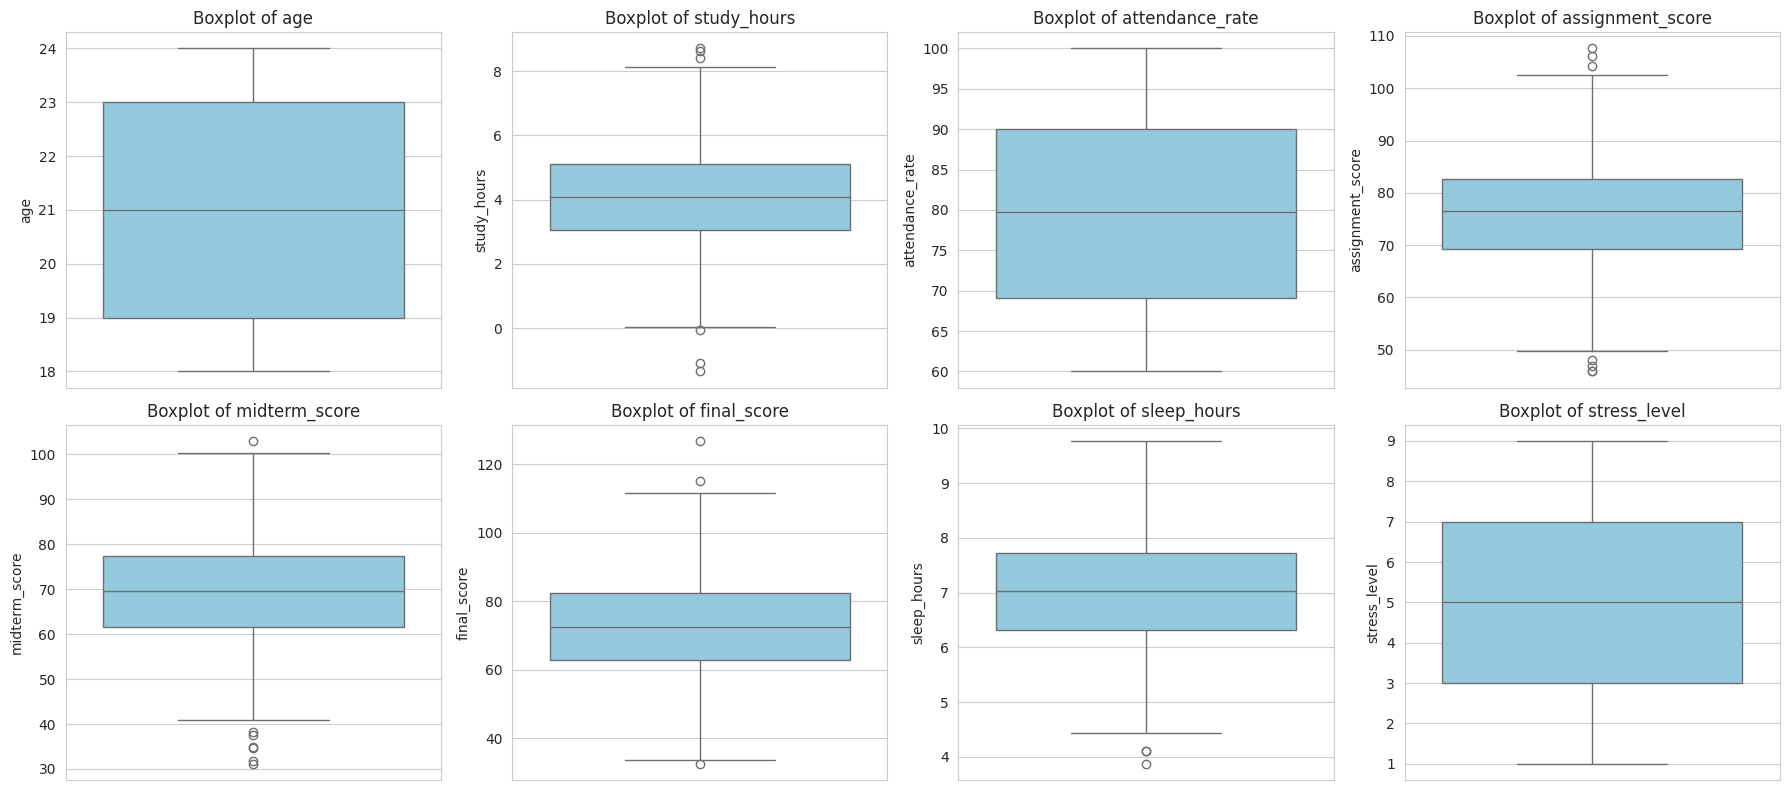

In [11]:
plot_cols = [
    "age",
    "study_hours",
    "attendance_rate",
    "assignment_score",
    "midterm_score",
    "final_score",
    "sleep_hours",
    "stress_level"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flatten(), plot_cols):
    sns.boxplot(y=raw_df[col], ax=ax, color="skyblue")
    ax.set_title("Boxplot of " + col)

plt.tight_layout()
plt.show()

**Description:** Boxplots show the distribution of each numerical attribute using the median, quartiles, spread, and potential outliers.

**What it tells us:** The boxplots reveal potential outliers in several numerical attributes. Some values are domain-invalid, such as negative `study_hours` and scores above 100, while other extreme values may still be logically valid.

**Decision:** Domain-invalid values should be corrected using valid boundaries, while statistically extreme but logically valid values can be retained.

### 3.3.5 Histograms (variable distributions of numeric attributes)

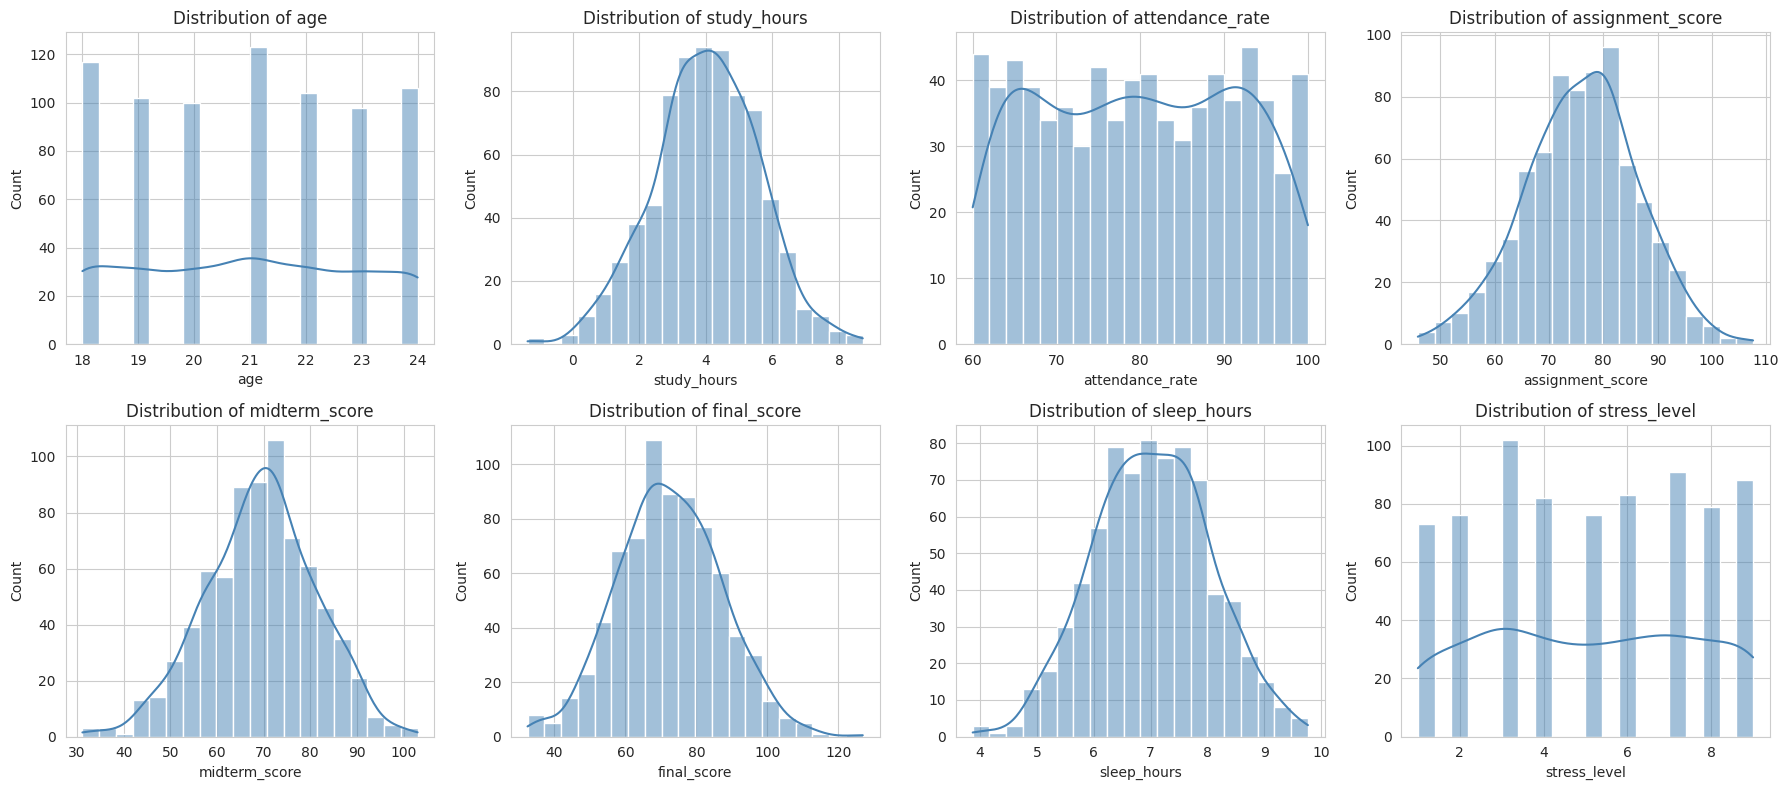

age                 0.02
study_hours        -0.09
attendance_rate     0.01
assignment_score   -0.11
midterm_score      -0.14
final_score         0.09
sleep_hours         0.01
stress_level        0.00
dtype: float64


In [12]:
hist_cols = ["age", "study_hours", "attendance_rate", "assignment_score",
             "midterm_score", "final_score", "sleep_hours", "stress_level"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), hist_cols):
    sns.histplot(raw_df[col], bins=20, kde=True, ax=ax, color="steelblue")
    ax.set_title("Distribution of " + col)
plt.tight_layout()
plt.show()

print(raw_df[hist_cols].skew().round(2))

**Description:** Histograms show the distribution of each numerical attribute, while the density curve and skewness values help describe the shape and symmetry of the distributions.

**What it tells us:** Most numerical attributes are approximately symmetric, with skewness values close to zero, so no skewness correction is needed. However, the numerical attributes have different ranges, and some score attributes contain extreme values beyond their valid limits.

**Decision:** Normalization is needed for selected numerical attributes with different ranges to place them on a common scale, while domain-invalid values are handled separately during noise removal.

### 3.3.6 Scatter Plots

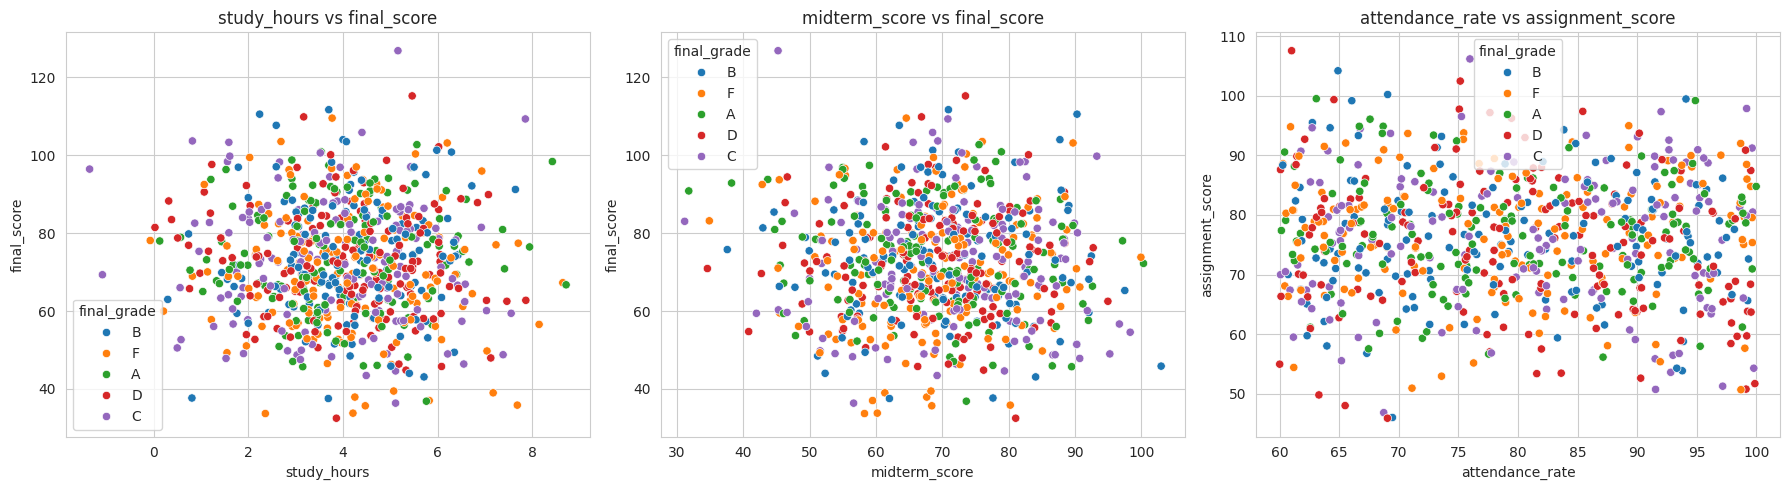

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=raw_df, x="study_hours", y="final_score", hue=target, ax=axes[0])
axes[0].set_title("study_hours vs final_score")
sns.scatterplot(data=raw_df, x="midterm_score", y="final_score", hue=target, ax=axes[1])
axes[1].set_title("midterm_score vs final_score")
sns.scatterplot(data=raw_df, x="attendance_rate", y="assignment_score", hue=target, ax=axes[2])
axes[2].set_title("attendance_rate vs assignment_score")
plt.tight_layout()
plt.show()

**Description:** Scatter plots of pairs of numeric attributes, coloured by the class label.  
**What it tells us:** The points are spread without a clear pattern (no strong linear relationship between the pairs), and the grade colours are mixed everywhere. The extreme points (negative `study_hours`, `final_score` above 100) are clearly separated from the main cloud.  
**Decision:** Confirms that the extreme points are noise that should be treated.

### 3.3.7 Bar Plots (nominal attributes)

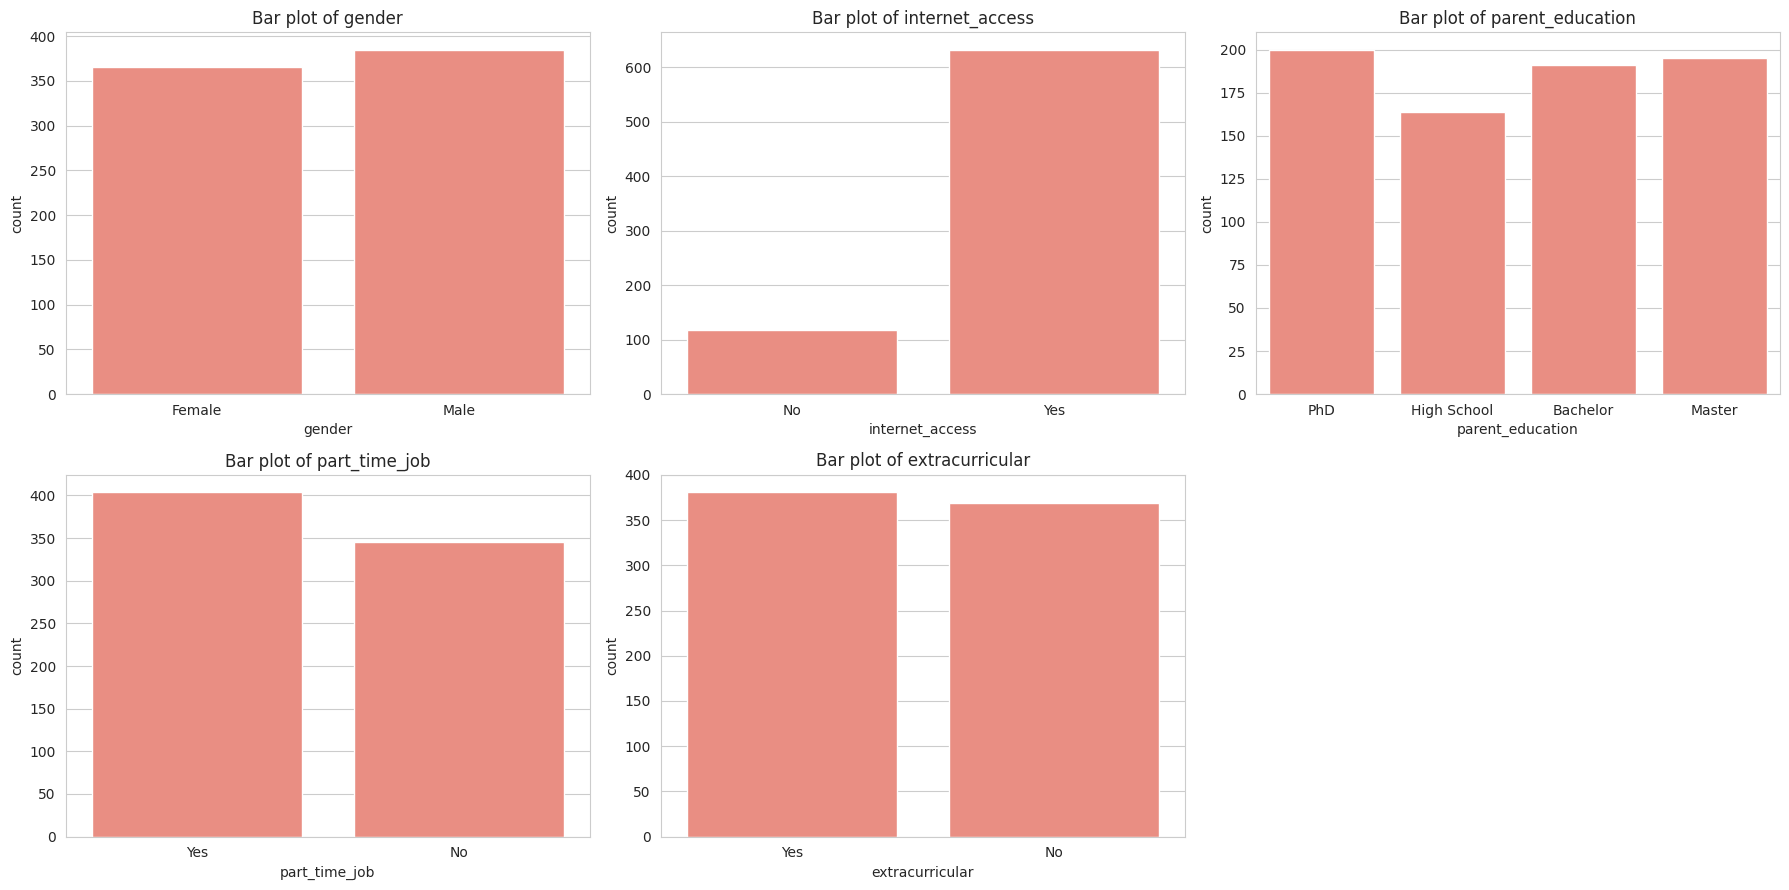

gender
Male      385
Female    365
Name: count, dtype: int64

internet_access
Yes    632
No     118
Name: count, dtype: int64

parent_education
PhD            200
Master         195
Bachelor       191
High School    164
Name: count, dtype: int64

part_time_job
Yes    404
No     346
Name: count, dtype: int64

extracurricular
Yes    381
No     369
Name: count, dtype: int64



In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flatten(), categorical_cols):
    sns.countplot(data=raw_df, x=col, ax=ax, color="salmon")
    ax.set_title("Bar plot of " + col)
axes[1][2].axis("off")
plt.tight_layout()
plt.show()

for col in categorical_cols:
    print(raw_df[col].value_counts())
    print()

**Description:** Bar plots of the count of each category in the nominal attributes.  
**What it tells us:** The categories are fairly balanced, except `internet_access` (632 Yes vs 118 No). `gender`, `internet_access`, `part_time_job` and `extracurricular` have two values, and `parent_education` has four values (High School, Bachelor, Master, PhD) with a natural order. These attributes are stored as text.  
**Decision:** Categorical variable transformation is needed because the algorithms require numeric input.

### 3.3.8 Class Label Distribution

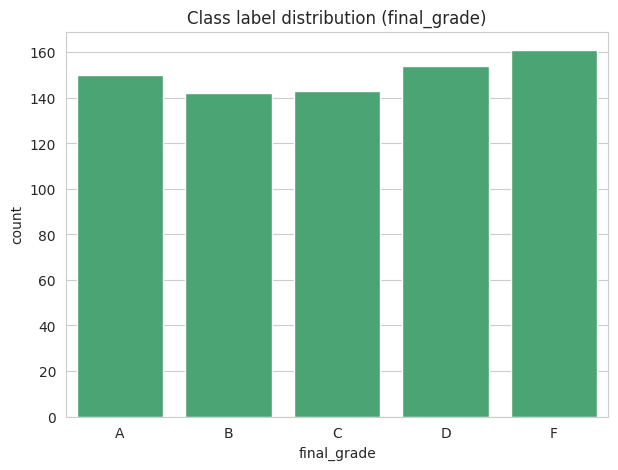

final_grade
A    150
B    142
C    143
D    154
F    161
Name: count, dtype: int64

final_grade
A    20.0
B    18.9
C    19.1
D    20.5
F    21.5
Name: proportion, dtype: float64


In [15]:
order = ["A", "B", "C", "D", "F"]
plt.figure(figsize=(7, 5))
sns.countplot(data=raw_df, x=target, order=order, color="mediumseagreen")
plt.title("Class label distribution (final_grade)")
plt.show()

print(raw_df[target].value_counts().reindex(order))
print()
print((raw_df[target].value_counts(normalize=True).reindex(order) * 100).round(1))

**Description:** Number of records in each class of `final_grade`.  
**What it tells us:** The five classes are almost balanced (A 150, B 142, C 143, D 154, F 161), so there is no class imbalance problem.  
**Decision:** No resampling is needed, and the original class distribution is preserved.

# 4. Data Preprocessing

The following original Phase 2 code applies noise removal, discretization, categorical transformation, and normalization. It saves a separate preprocessed CSV in the existing GitHub Dataset folder.

According to the phase guidelines, we apply appropriate preprocessing tasks chosen from the recommended techniques: **Noise Removal**, **Discretization**, **Normalization** and **Variable Transformation (Categorical)**

## 4.1 Noise Removal

**Justification:** The attributes `study_hours`, `assignment_score`, `midterm_score`, and `final_score` contain domain-invalid values. Negative study hours and scores above 100 are not logically valid and may result from data entry errors or uncalibrated extra credit.

**Method:** Domain boundary clamping was applied by setting the lower threshold of `study_hours` to 0.0 and capping `assignment_score`, `midterm_score`, and `final_score` at 100.0.

**Improvement:** This corrects invalid values while preserving the relative ordering of students, avoiding unnecessary removal of records or replacement of valid extreme values.

In [16]:
print("--- Preprocessing: Noise Removal (Domain Boundary Clamping) ---")

df["study_hours"] = df["study_hours"].clip(lower=0.0)
for col in ["assignment_score", "midterm_score", "final_score"]:
  df[col] = df[col].clip(upper=100.0)

print("Updated ranges after domain boundary clamping:")
df[["study_hours", "assignment_score", "midterm_score", "final_score"]].describe().T[["min", "mean", "max"]]

--- Preprocessing: Noise Removal (Domain Boundary Clamping) ---
Updated ranges after domain boundary clamping:


,min,mean,max
study_hours,0.00,4.018253,8.71
assignment_score,45.86,75.990187,100.00
midterm_score,31.13,69.402507,100.00
final_score,32.46,72.312093,100.00


## 4.2 Discretization

**Justification:** `age` and `study_hours` were selected because they are numerical attributes that can be meaningfully grouped into categories, making the data easier to interpret and analyze.

**Method:** Discretization was applied using `pd.cut()` with three bins. `age` was divided into Young, Middle, and Older, while `study_hours` was divided into Low, Medium, and High.

**Improvement:** This transformation groups numerical values into categorical intervals, simplifying the data representation and making patterns in `age` and `study_hours` easier to analyze.

In [17]:
column_to_discretize = "age"
num_bins = 3
df["discretized_age"] = pd.cut(
    df[column_to_discretize],
    bins=num_bins,
    labels=["Young", "Middle", "Older"])
print("Original DataFrame:")
display(df[["age", "discretized_age"]].head(15))

Original DataFrame:


,age,discretized_age
0,24,Older
1,21,Middle
2,22,Middle
3,24,Older
4,20,Young
5,22,Middle
6,22,Middle
7,24,Older
8,19,Young
9,20,Young


In [18]:
column_to_discretize = "study_hours"
num_bins = 3
df["discretized_study_hours"] = pd.cut(
    df[column_to_discretize],
    bins=num_bins,
    labels=["Low", "Medium", "High"])
print("Original DataFrame:")
display(df[["study_hours", "discretized_study_hours"]].head(15))

Original DataFrame:


,study_hours,discretized_study_hours
0,3.06,Medium
1,3.26,Medium
2,4.63,Medium
3,3.42,Medium
4,2.15,Low
5,2.35,Low
6,4.81,Medium
7,1.96,Low
8,6.10,High
9,2.96,Medium


## 4.3 Variable Transformation (Categorical)

**Justification:** Machine learning algorithms require numerical inputs and cannot directly perform mathematical operations on textual categorical data such as `gender`, `internet_access`, `parent_education`, `part_time_job`, `extracurricular`, and `final_grade`.

**Method:** Binary mapping (0/1) was applied to the two-category nominal attributes `gender`, `internet_access`, `part_time_job`, and `extracurricular`. Ordinal mapping was applied to `parent_education` (0 to 3) and `final_grade` (0 to 4) to preserve their natural order.

**Improvement:** This transformation converts categorical attributes into numerical formats compatible with data mining methods while preserving the meaningful order of education levels and letter grades without adding unnecessary columns.

In [19]:
# 1. Binary nominal
df['gender_transformed'] = df['gender'].map({'Female': 1, 'Male': 0})
df['internet_access_transformed'] = df['internet_access'].map({'Yes': 1, 'No': 0})
df['part_time_job_transformed'] = df['part_time_job'].map({'Yes': 1, 'No': 0})
df['extracurricular_transformed'] = df['extracurricular'].map({'Yes': 1, 'No': 0})
# 2. Ordinal variable
df['parent_education_transformed'] = df['parent_education'].map({'High School': 0, 'Bachelor': 1, 'Master': 2, 'PhD': 3})
# 3. Target class label mapped to standard academic grade order
df['final_grade_transformed'] = df['final_grade'].map({'F': 0, 'D': 1, 'C': 2, 'B': 3, 'A': 4})

display(df[[
    'gender', 'gender_transformed',
    'parent_education', 'parent_education_transformed',
    'internet_access','internet_access_transformed',
    'part_time_job', 'part_time_job_transformed' ,
    'extracurricular' , 'extracurricular_transformed',
    'final_grade', 'final_grade_transformed'
]].head(5))

,gender,gender_transformed,parent_education,parent_education_transformed,internet_access,internet_access_transformed,part_time_job,part_time_job_transformed,extracurricular,extracurricular_transformed,final_grade,final_grade_transformed
0,Female,1,PhD,3,No,0,Yes,1,Yes,1,B,3
1,Male,0,High School,0,Yes,1,Yes,1,No,0,F,0
2,Female,1,Bachelor,1,No,0,No,0,No,0,F,0
3,Female,1,High School,0,Yes,1,No,0,Yes,1,F,0
4,Male,0,Master,2,Yes,1,No,0,Yes,1,F,0


## 4.4 Normalization

**Justification:** The selected numerical attributes (`attendance_rate`, `assignment_score`, `midterm_score`, `final_score`, and `stress_level`) have different numerical ranges. Normalization is applied to place these attributes on a common scale and prevent attributes with larger ranges from having a greater influence on distance-based analysis.

**Method:** Min-Max normalization was applied to `attendance_rate`, `assignment_score`, `midterm_score`, `final_score`, and `stress_level`, transforming their values to the range [0, 1]. The attributes `student_id`, `age`, `study_hours`, and `sleep_hours` were excluded from normalization, along with categorical attributes and the target variable `final_grade`.

**Improvement:** The selected numerical attributes are now represented on the same scale, reducing the effect of differences in their original ranges. This improves their suitability for distance-based data mining methods such as clustering.

In [20]:
# Numerical attributes selected for normalization
cols_to_normalize = [
    "attendance_rate",
    "assignment_score",
    "midterm_score",
    "final_score",
    "stress_level"
]

# Check ranges before normalization
print("Numeric attribute ranges before normalization:")
df[cols_to_normalize].agg(["min", "max"]).T

Numeric attribute ranges before normalization:


,min,max
attendance_rate,60.01,99.99
assignment_score,45.86,100.00
midterm_score,31.13,100.00
final_score,32.46,100.00
stress_level,1.00,9.00


In [21]:
# Apply Min-Max normalization
scaler = MinMaxScaler()

df[cols_to_normalize] = scaler.fit_transform(df[cols_to_normalize])

print("Ranges after Min-Max normalization:")
df[cols_to_normalize].agg(["min", "max"]).T

Ranges after Min-Max normalization:


,min,max
attendance_rate,0.0,1.0
assignment_score,0.0,1.0
midterm_score,0.0,1.0
final_score,0.0,1.0
stress_level,0.0,1.0


In [22]:
# Check that the raw data was not modified
raw_check = pd.read_excel("Dataset/raw_dataset.xlsx")
print("Raw data unchanged:", raw_df.equals(raw_check))

print("Preprocessed Dataset:")
display(df.head())

df.to_csv("Dataset/Preprocessed_dataset.csv", index=False)

print("Preprocessed dataset saved successfully!")
print("Final shape:", df.shape)

Raw data unchanged: True
Preprocessed Dataset:


,student_id,age,gender,study_hours,attendance_rate,assignment_score,midterm_score,final_score,internet_access,parent_education,...,extracurricular,final_grade,discretized_age,discretized_study_hours,gender_transformed,internet_access_transformed,part_time_job_transformed,extracurricular_transformed,parent_education_transformed,final_grade_transformed
0,1,24,Female,3.06,0.248374,0.675286,0.511979,0.728753,No,PhD,...,Yes,B,Older,Medium,1,0,1,1,3,3
1,2,21,Male,3.26,0.133567,0.572774,0.054015,0.750814,Yes,High School,...,No,F,Middle,Medium,0,1,1,0,0,0
2,3,22,Female,4.63,0.418459,0.789989,0.543343,0.380367,No,Bachelor,...,No,F,Middle,Medium,1,0,0,0,1,0
3,4,24,Female,3.42,0.790395,0.384559,0.760418,0.696328,Yes,High School,...,Yes,F,Older,Medium,1,1,0,1,0,0
4,5,20,Male,2.15,0.582291,0.518471,0.565558,0.620669,Yes,Master,...,Yes,F,Young,Low,0,1,0,1,2,0


Preprocessed dataset saved successfully!
Final shape: (750, 23)


# 5. Data Mining Technique

## 5.1 Classification: Decision Tree

**Why:** A decision tree recursively splits the data on the attribute that best separates the classes and produces human-readable rules [4]. It was chosen because the project needs to explain *which factors drive the grade*, not only predict it.

**How:**
- **Packages:** `sklearn.tree.DecisionTreeClassifier`, `sklearn.model_selection.train_test_split`, `sklearn.metrics` (`accuracy_score`, `f1_score`, `confusion_matrix`, `ConfusionMatrixDisplay`) and `sklearn.tree.plot_tree` for the tree drawing [5].
- **Attribute selection measures:** Gini index (`criterion="gini"`) and Information Gain (`criterion="entropy"`).
- **Partitions:** 70/30, 80/20 and 90/10 training/testing splits (`random_state=1`), giving 6 experiments (3 partitions × 2 measures).
- **Class label:** `final_grade` (A, B, C, D, F). The ID, the text columns and `final_score` are excluded (Section 2).
- **Features (18):** age, study_hours, attendance_rate, assignment_score, midterm_score, sleep_hours, stress_level, the five transformed binary/ordinal attributes (gender, internet access, part-time job, extracurricular, parent education), and the one-hot encoded discretized age and study hours (`pd.get_dummies`).
- **Evaluation:** testing accuracy, weighted F1-score, training accuracy (to detect overfitting) and a confusion matrix for every experiment. The trees are grown without pruning (default parameters).

## 5.2 Clustering: K-Means

**Why:** K-means partitions the students into k groups by minimising the distance between each student and the centre of their group [4]. It was chosen because it is simple, efficient for 750 records, and its centroids are easy to interpret.

**How:**
- **Packages:** `sklearn.cluster.KMeans` (`random_state=42`, `n_init=25`), `sklearn.preprocessing.StandardScaler`, `sklearn.metrics.silhouette_score` / `silhouette_samples`, and `sklearn.decomposition.PCA` for two-dimensional visualisation only [5].
- **Attributes (12):** age, study_hours, attendance_rate, assignment_score, midterm_score, final_score, sleep_hours, stress_level, internet_access, part_time_job, extracurricular, parent_education. The class label, gender, the student ID, the text columns and the discretized columns are excluded.
- **Scaling:** a z-score `StandardScaler` is applied to all 12 attributes so that every attribute, including the binary ones, contributes equally to the Euclidean distance.
- **Choice of k (three values, three methods):** the empirical rule k ≈ √(n/2) = √(750/2) ≈ 19 [4], the Elbow method on the within-cluster sum of squares (k = 3), and the maximum average silhouette (k = 2).
- **Evaluation:** total within-cluster sum of squares (WSS), average silhouette width, silhouette plots, and PCA scatter plots of the clusters for each k.


# 6. Evaluation and Comparison

## 6.1 Classification — Decision Tree

The following cells retain the Phase 3 classification experiments, comparison table, confusion matrices, and decision-tree visualization.

In [23]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn import tree
import matplotlib.pyplot as plt

In [24]:
# Load the preprocessed student dataset
df = pd.read_csv("Dataset/Preprocessed_dataset.csv")
print(df.head())

# Use final_grade as the target
y = df['final_grade']

# Remove the ID, target, and columns we do not need
X = df.drop(columns=[
    'student_id',
    'final_grade',
    'final_grade_transformed',
    'final_score',
    'gender',
    'internet_access',
    'parent_education',
    'part_time_job',
    'extracurricular'
])

# Convert the remaining categorical columns into numbers
X = pd.get_dummies(X)

fn = X.columns.tolist()

print("Features:", fn)
print("Dataset shape:", X.shape)

   student_id  age  gender  study_hours  attendance_rate  assignment_score  \
0           1   24  Female         3.06         0.248374          0.675286   
1           2   21    Male         3.26         0.133567          0.572774   
2           3   22  Female         4.63         0.418459          0.789989   
3           4   24  Female         3.42         0.790395          0.384559   
4           5   20    Male         2.15         0.582291          0.518471   

   midterm_score  final_score internet_access parent_education  ...  \
0       0.511979     0.728753              No              PhD  ...   
1       0.054015     0.750814             Yes      High School  ...   
2       0.543343     0.380367              No         Bachelor  ...   
3       0.760418     0.696328             Yes      High School  ...   
4       0.565558     0.620669             Yes           Master  ...   

   extracurricular final_grade  discretized_age discretized_study_hours  \
0              Yes           

In [25]:

# Try three different training and testing splits
partitions = {
    "70/30": 0.3,
    "80/20": 0.2,
    "90/10": 0.1
}

In [26]:

# Compare Gini and Entropy to see which one works better
criteria = ['gini', 'entropy']

results = []
result_matrices = []
best_accuracy = -1


In [27]:

# Train and test the Decision Tree using different splits
for partition, test_size in partitions.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=1
    )

    # Try Gini and Entropy for each split
    for criterion in criteria:

        clf = DecisionTreeClassifier(
            criterion=criterion,
            random_state=1
        )

        clf = clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        # Check how well the model performs
        accuracy = metrics.accuracy_score(y_test, y_pred)

        train_accuracy = metrics.accuracy_score(
            y_train, clf.predict(X_train)
        )

        f1 = metrics.f1_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        )

        cm = confusion_matrix(
            y_test, y_pred,
            labels=clf.classes_
        )

        print("\nPartition:", partition)
        print("Criterion:", criterion)
        print("Training Accuracy:", train_accuracy)
        print("Testing Accuracy:", accuracy)
        print("F1-score:", f1)
        print("Confusion Matrix:")
        print(cm)

        # Save the results to compare them later
        results.append({
            "Partition": partition,
            "Criterion": criterion,
            "Training Accuracy": train_accuracy,
            "Accuracy": accuracy,
            "F1-score": f1
        })

        # Save each confusion matrix for the plots
        result_matrices.append({
            "Partition": partition,
            "Criterion": criterion,
            "Matrix": cm,
            "Labels": clf.classes_
        })

        # Keep the model with the highest testing accuracy
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_clf = clf
            best_partition = partition
            best_criterion = criterion



Partition: 70/30
Criterion: gini
Training Accuracy: 1.0
Testing Accuracy: 0.2088888888888889
F1-score: 0.20653677270543852
Confusion Matrix:
[[15  9  4 10 10]
 [13  4  7  8 12]
 [ 7  8 10  7  2]
 [11 13 10  8 11]
 [ 7 11  8 10 10]]

Partition: 70/30
Criterion: entropy
Training Accuracy: 1.0
Testing Accuracy: 0.24888888888888888
F1-score: 0.24168198584809636
Confusion Matrix:
[[ 8  7 14 10  9]
 [13 17  6  4  4]
 [ 6  8 13  5  2]
 [ 7 12 13 10 11]
 [11 11  7  9  8]]

Partition: 80/20
Criterion: gini
Training Accuracy: 1.0
Testing Accuracy: 0.2
F1-score: 0.20021340598060458
Confusion Matrix:
[[ 5  5  5  6  6]
 [ 6  4 11 11  1]
 [ 3  4  6  7  3]
 [ 7  6  8  8  5]
 [ 9  7  5  5  7]]

Partition: 80/20
Criterion: entropy
Training Accuracy: 1.0
Testing Accuracy: 0.26666666666666666
F1-score: 0.2702947670934154
Confusion Matrix:
[[ 6  2  6  6  7]
 [ 9  7  7  5  5]
 [ 4  4  5  5  5]
 [ 4  4  7 12  7]
 [10  5  5  3 10]]

Partition: 90/10
Criterion: gini
Training Accuracy: 1.0
Testing Accuracy: 0

In [28]:

# Put all six results in one table
results_df = pd.DataFrame(results)

print("Comparison Results:")
print(results_df.to_string(index=False))

# Show the best result from our experiments
print("\nBest Partition:", best_partition)
print("Best Criterion:", best_criterion)
print("Best Accuracy:", best_accuracy)


Comparison Results:
Partition Criterion  Training Accuracy  Accuracy  F1-score
    70/30      gini                1.0  0.208889  0.206537
    70/30   entropy                1.0  0.248889  0.241682
    80/20      gini                1.0  0.200000  0.200213
    80/20   entropy                1.0  0.266667  0.270295
    90/10      gini                1.0  0.173333  0.167267
    90/10   entropy                1.0  0.253333  0.253775

Best Partition: 80/20
Best Criterion: entropy
Best Accuracy: 0.26666666666666666


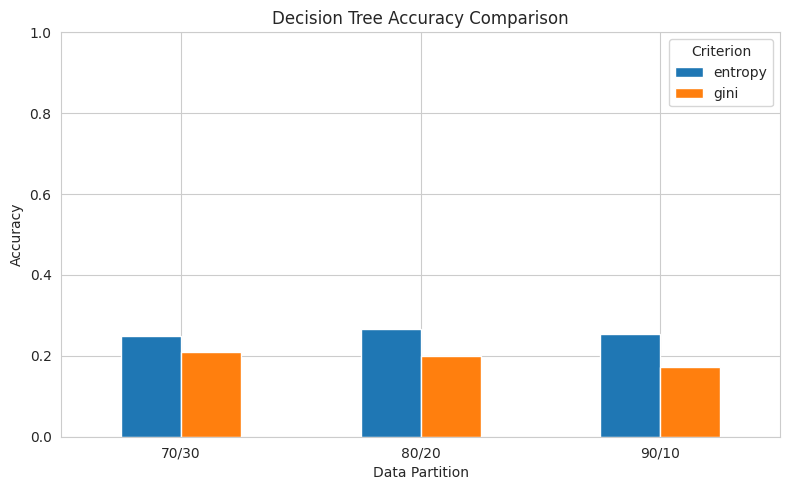

In [29]:

# Compare the accuracy of Gini and Entropy
accuracy_table = results_df.pivot(
    index="Partition",
    columns="Criterion",
    values="Accuracy"
)

accuracy_table = accuracy_table.reindex(
    ["70/30", "80/20", "90/10"]
)

accuracy_table.plot(kind="bar", figsize=(8, 5))

plt.title("Decision Tree Accuracy Comparison")
plt.xlabel("Data Partition")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Criterion")
plt.tight_layout()
plt.show()


In [30]:
# Required summary tables: one table for each attribute selection measure
col_order = ["90/10", "80/20", "70/30"]
col_titles = {"90/10": "90% training / 10% testing",
              "80/20": "80% training / 20% testing",
              "70/30": "70% training / 30% testing"}

for criterion, title in [("gini", "Gini index"), ("entropy", "Information Gain (entropy)")]:
    sub_df = results_df[results_df["Criterion"] == criterion].set_index("Partition").reindex(col_order)
    table = pd.DataFrame({
        col_titles[p]: [f"{sub_df.loc[p, 'Accuracy'] * 100:.2f}%",
                        f"{sub_df.loc[p, 'F1-score']:.3f}",
                        f"{sub_df.loc[p, 'Training Accuracy'] * 100:.0f}%"]
        for p in col_order
    }, index=["Accuracy (testing)", "F1-score (weighted)", "Training accuracy"])
    print(f"Decision tree results using {title}")
    print(table.to_string())
    print()

# Best attribute selection measure for each partition
best_rows = []
for p in col_order:
    g = accuracy_table.loc[p, "gini"]
    e = accuracy_table.loc[p, "entropy"]
    best_rows.append({"Partition": p,
                      "Gini": f"{g * 100:.2f}%",
                      "Entropy": f"{e * 100:.2f}%",
                      "Best": "Entropy" if e > g else "Gini"})
print("Best attribute selection measure per partition")
print(pd.DataFrame(best_rows).to_string(index=False))
print(f"\nBest overall: {best_criterion} with the {best_partition} partition "
      f"(accuracy = {best_accuracy * 100:.2f}%)")

Decision tree results using Gini index
                    90% training / 10% testing 80% training / 20% testing 70% training / 30% testing
Accuracy (testing)                      17.33%                     20.00%                     20.89%
F1-score (weighted)                      0.167                      0.200                      0.207
Training accuracy                         100%                       100%                       100%

Decision tree results using Information Gain (entropy)
                    90% training / 10% testing 80% training / 20% testing 70% training / 30% testing
Accuracy (testing)                      25.33%                     26.67%                     24.89%
F1-score (weighted)                      0.254                      0.270                      0.242
Training accuracy                         100%                       100%                       100%

Best attribute selection measure per partition
Partition   Gini Entropy    Best
    90/10 17.33%

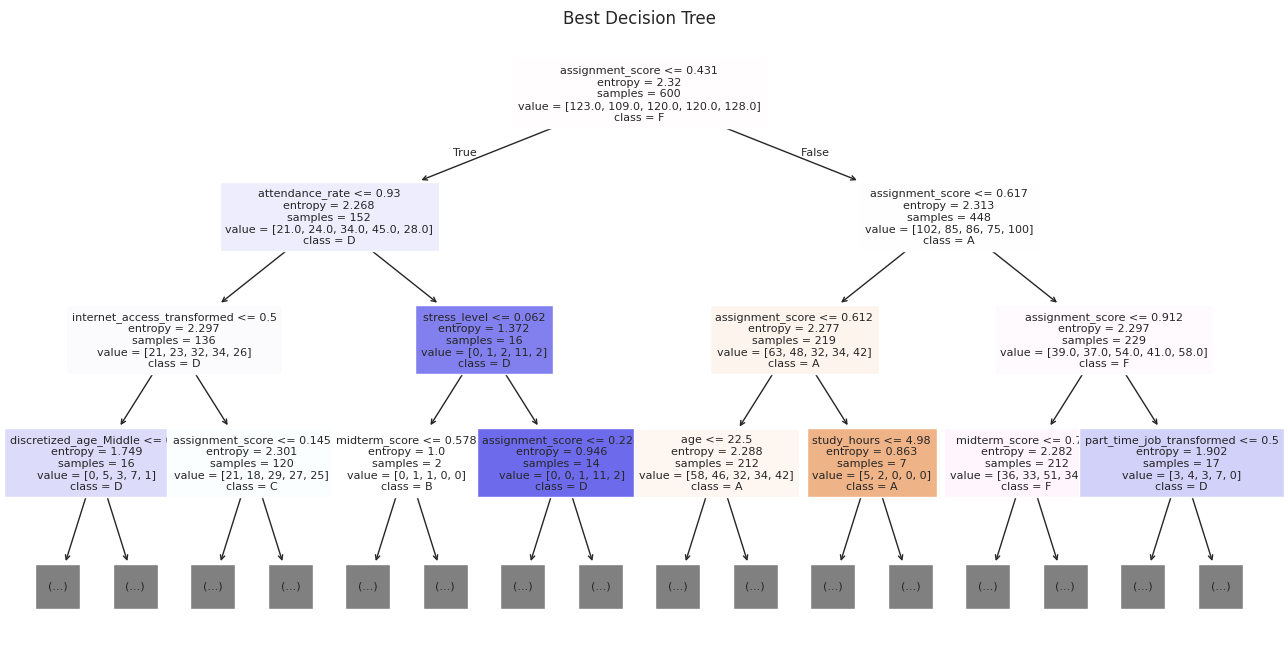

In [31]:

# Draw the tree to see how the model makes its decisions
plt.figure(figsize=(16, 8))

tree.plot_tree(
    best_clf,
    feature_names=fn,
    class_names=[str(c) for c in best_clf.classes_],
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("Best Decision Tree")
plt.show()


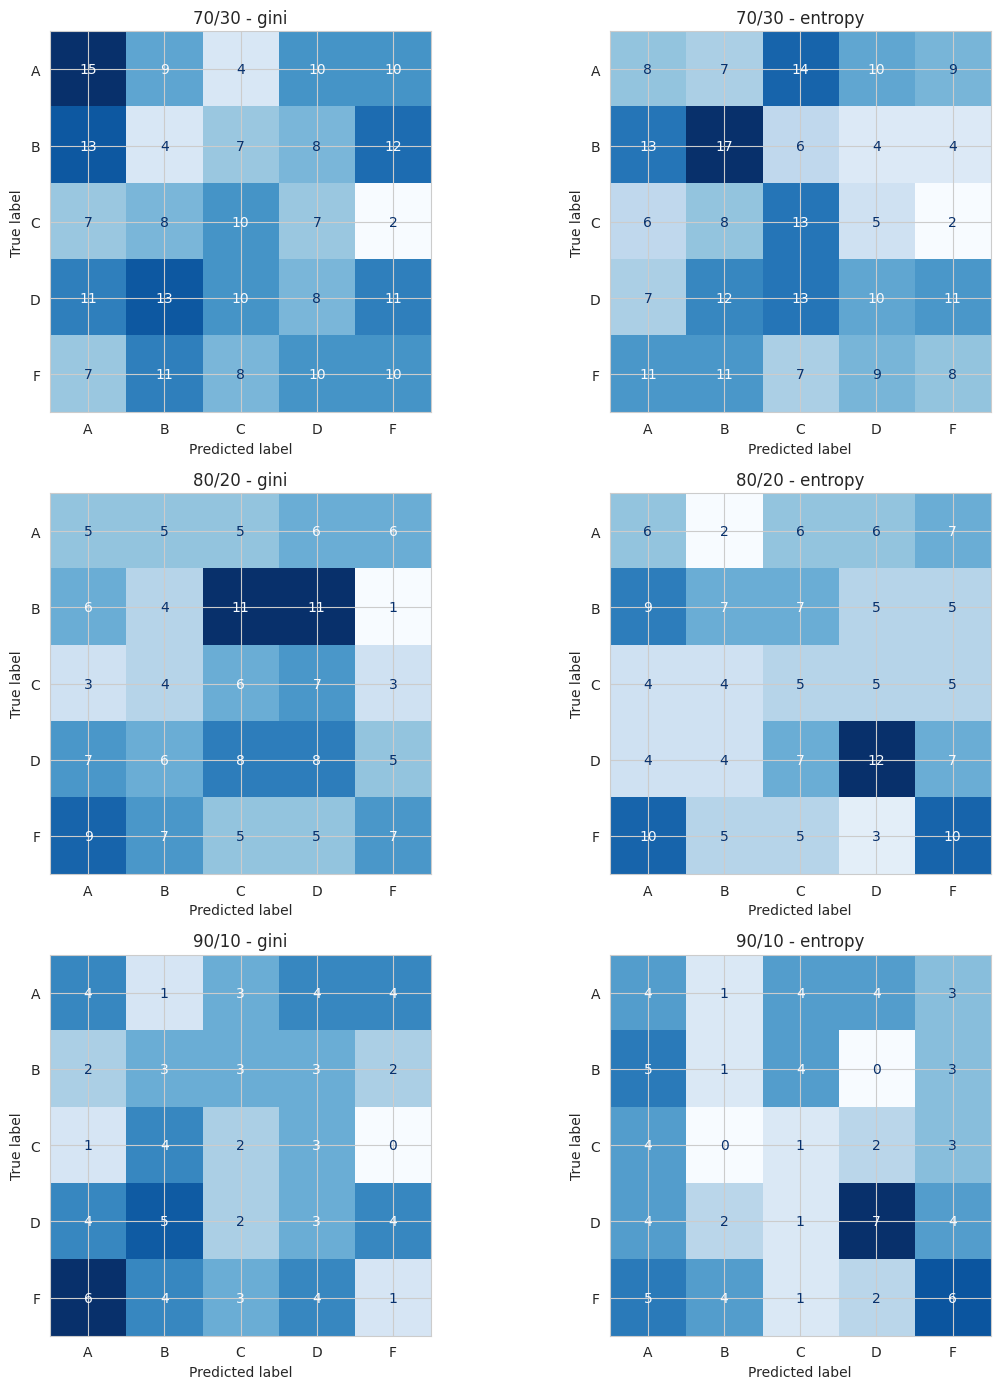

In [32]:

# Show the confusion matrix for all six experiments
fig, axes = plt.subplots(3, 2, figsize=(12, 14))

for ax, result in zip(axes.flat, result_matrices):

    disp = metrics.ConfusionMatrixDisplay(
        confusion_matrix=result["Matrix"],
        display_labels=result["Labels"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(
        result["Partition"] + " - " + result["Criterion"]
    )

plt.tight_layout()
plt.show()


**Description:** The tables above summarise Decision Tree classification with the two attribute selection measures (Gini index and Information Gain / entropy) on three partitions of the data (90/10, 80/20 and 70/30), together with the weighted F1-score and the training accuracy of each model.

**What it tells us:**
- **Gini:** testing accuracy is 17.33% (90/10), 20.00% (80/20) and 20.89% (70/30), which is about the 20% expected from random guessing among five balanced classes.
- **Entropy:** testing accuracy is 25.33% (90/10), 26.67% (80/20) and 24.89% (70/30), so entropy is better than Gini in every partition (by 8.00, 6.67 and 4.00 percentage points respectively).
- **Training accuracy is 100% in all six models**, while testing accuracy is only 17% to 27%. The unpruned trees memorise the training data instead of learning general rules (overfitting).

**Conclusion:** The best model for each partition is entropy, and the best model overall is **entropy with the 80/20 partition (accuracy 26.67%, F1 = 0.270)**. Even so, it is only about 7 percentage points above chance, so the result should be interpreted with caution. The confusion matrices above are discussed in Section 7.1.2.


## 6.2 Clustering — K-Means

The following cells retain the Phase 3 clustering experiments, selection of K, evaluation plots, and comparisons.

### 6.2.1 Preparing the Data for Clustering

In [33]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [34]:
# Load
df = pd.read_csv("Dataset/Preprocessed_dataset.csv")

# Keep the class label aside
target = df["final_grade"]

# Remove the ID, the class label, and the text columns
# (the text columns already have numeric versions ending in _transformed)
# We also remove gender, because we want clusters based on student behaviour and performance
features = df.drop(columns=[
    "student_id",
    "final_grade",
    "final_grade_transformed",
    "gender",
    "gender_transformed",
    "internet_access",
    "parent_education",
    "part_time_job",
    "extracurricular",
    "discretized_age",
    "discretized_study_hours"
])

# Scale the features so no attribute dominates the distance
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)
SG_scaled = pd.DataFrame(scaled_features, columns=features.columns)

print("Features:", SG_scaled.columns.tolist())
print("Dataset shape:", SG_scaled.shape)
print("\nScaled DataFrame:")
print(SG_scaled.head())

Features: ['age', 'study_hours', 'attendance_rate', 'assignment_score', 'midterm_score', 'final_score', 'sleep_hours', 'stress_level', 'internet_access_transformed', 'part_time_job_transformed', 'extracurricular_transformed', 'parent_education_transformed']
Dataset shape: (750, 12)

Scaled DataFrame:
        age  study_hours  attendance_rate  assignment_score  midterm_score  \
0  1.522341    -0.615343        -0.838550          0.624783      -0.256269   
1  0.024629    -0.486913        -1.230996          0.085491      -2.939325   
2  0.523866     0.392834        -0.257149          1.228207      -0.072521   
3  1.522341    -0.384169         1.014238         -0.904668       1.199251   
4 -0.474608    -1.199701         0.302877         -0.200188       0.057633   

   final_score  sleep_hours  stress_level  internet_access_transformed  \
0     0.662191     0.437271     -1.198128                    -2.314289   
1     0.767515    -0.156688      0.366008                     0.432098   
2    -1

### 6.2.2 Choosing the Number of Clusters (k)

#### 6.2.2.1 The empirical rule

In [35]:
# Empirical rule: k= the square root of n/2
n = len(SG_scaled)
empirical_k = np.sqrt(n / 2)

print("Number of objects (n):", n)
print("sqrt(n/2) =", round(empirical_k, 2))
print("Chosen k from the empirical rule:", round(empirical_k))

Number of objects (n): 750
sqrt(n/2) = 19.36
Chosen k from the empirical rule: 19


#### 6.2.2.2 The Elbow method (WSS only)

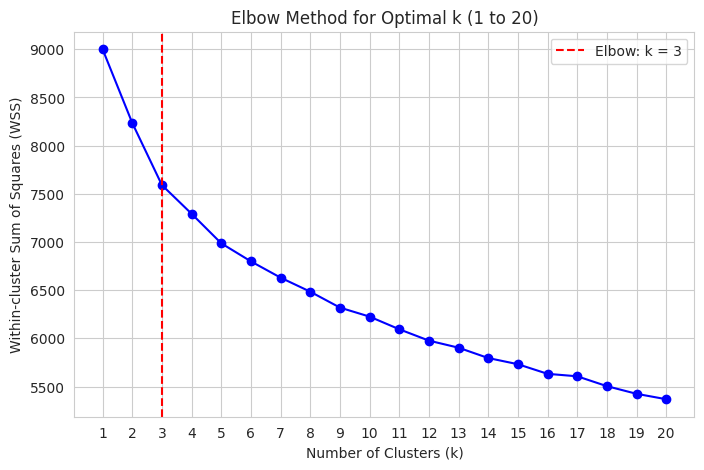

k = 1 -> 2: WSS drops by 764.6
k = 2 -> 3: WSS drops by 644.9
k = 3 -> 4: WSS drops by 297.6
k = 4 -> 5: WSS drops by 306.5
k = 5 -> 6: WSS drops by 187.5
k = 6 -> 7: WSS drops by 168.9
k = 7 -> 8: WSS drops by 145.6
k = 8 -> 9: WSS drops by 165.0
k = 9 -> 10: WSS drops by 93.7


In [36]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Elbow method: run k-means for k = 1 to 20 and record the WSS
k_values = list(range(1, 21))
wss_values = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=25)
    kmeans.fit(SG_scaled)
    wss_values.append(kmeans.inertia_)

# Plot the elbow curve (WSS only)
plt.figure(figsize=(8, 5))
plt.plot(k_values, wss_values, marker='o', linestyle='-', color='blue')
plt.axvline(x=3, linestyle='--', color='red', label='Elbow: k = 3')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-cluster Sum of Squares (WSS)')
plt.title('Elbow Method for Optimal k (1 to 20)')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

# Show how much the WSS drops each time we add a cluster
for i in range(1, 10):
    print(f"k = {k_values[i-1]} -> {k_values[i]}: WSS drops by {wss_values[i-1] - wss_values[i]:.1f}")

#### 6.2.2.3 The silhouette method (average silhouette only)

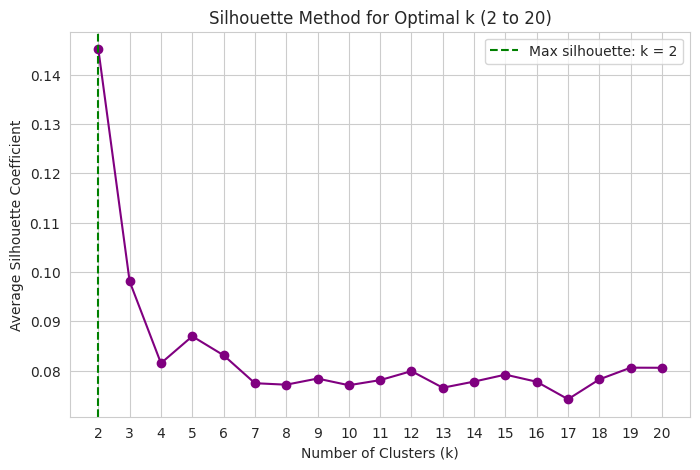

k = 2: average silhouette = 0.1452
k = 3: average silhouette = 0.0981
k = 4: average silhouette = 0.0815
k = 5: average silhouette = 0.0870
k = 6: average silhouette = 0.0831
k = 7: average silhouette = 0.0774
k = 8: average silhouette = 0.0771
k = 9: average silhouette = 0.0784
k = 10: average silhouette = 0.0770
k = 11: average silhouette = 0.0781
k = 12: average silhouette = 0.0799
k = 13: average silhouette = 0.0765
k = 14: average silhouette = 0.0778
k = 15: average silhouette = 0.0792
k = 16: average silhouette = 0.0777
k = 17: average silhouette = 0.0742
k = 18: average silhouette = 0.0782
k = 19: average silhouette = 0.0806
k = 20: average silhouette = 0.0806

Best k by silhouette: 2


In [37]:
from sklearn.metrics import silhouette_score

# Silhouette method: run k-means for k = 2 to 20 and record the average silhouette
sil_k_values = list(range(2, 21))
sil_values = []

for k in sil_k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=25)
    labels = kmeans.fit_predict(SG_scaled)
    sil_values.append(silhouette_score(SG_scaled, labels))

# Best k = the one that maximizes the average silhouette
best_k = sil_k_values[int(np.argmax(sil_values))]

# Plot the silhouette curve
plt.figure(figsize=(8, 5))
plt.plot(sil_k_values, sil_values, marker='o', linestyle='-', color='purple')
plt.axvline(x=best_k, linestyle='--', color='green',
            label=f'Max silhouette: k = {best_k}')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Average Silhouette Coefficient')
plt.title('Silhouette Method for Optimal k (2 to 20)')
plt.xticks(sil_k_values)
plt.legend()
plt.grid(True)
plt.show()

# Print the values
for k, s in zip(sil_k_values, sil_values):
    print(f"k = {k}: average silhouette = {s:.4f}")
print(f"\nBest k by silhouette: {best_k}")

**Description:** We used three methods from the lecture to choose the number of clusters.
The empirical rule gives k = √(750/2) ≈ 19.36, so k = 19.
The elbow method plots the total within-cluster sum of squares (WSS) for k = 1 to 20.
The silhouette method gives the highest average silhouette at k = 2.

**What it tells us:** The WSS always decreases as k increases. The largest drops are from k = 1 to 2 (765) and from k = 2 to 3 (645). After k = 3 the drop is less than half as large (298), and the curve keeps declining gradually. So the elbow is at k = 3. The elbow is not very sharp, which suggests that the students do not form strongly separated groups.

**Conclusion:** We selected three values of k: **k = 19** (empirical rule), **k = 3** (elbow method), and **k = 2** (highest average silhouette).

### 6.2.3 K-Means Clustering

In [38]:
# Set a fixed seed so the results are the same every time
np.random.seed(42)

# This function runs k-means for a given k and prints the results
def run_kmeans(k):

    # Run k-means clustering with k clusters
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=25)
    kmeans_result = kmeans.fit(SG_scaled)

    # Print the clustering result
    print(f"===== k = {k} =====")

    print("\nCluster Centers:")
    print(pd.DataFrame(kmeans_result.cluster_centers_, columns=SG_scaled.columns).round(2))

    print("\nCluster Labels (first 20):")
    print(kmeans_result.labels_[:20])

    print("\nObjects per cluster:")
    print(pd.Series(kmeans_result.labels_).value_counts().sort_index())

    return kmeans_result

**by Empirical Rule**

In [39]:
# 1st call: k = 19 (by empirical rule)
kmeans_result_19= run_kmeans(19)

===== k = 19 =====

Cluster Centers:
     age  study_hours  attendance_rate  assignment_score  midterm_score  \
0   0.05        -0.73             0.99              0.64           0.58   
1   0.45         0.66            -0.15             -0.47           0.49   
2  -0.19         0.16            -0.52              0.45          -0.08   
3   0.70        -0.58            -0.10             -0.08          -1.23   
4   0.62         0.78            -0.91              0.79           0.01   
5  -0.50         0.17            -0.51             -0.00           0.21   
6   0.68         0.14             0.09             -0.90           0.02   
7  -0.05         0.02             0.03              0.75          -0.02   
8   0.22         0.05             0.13              0.13           0.10   
9  -0.82         0.04            -0.62             -0.30          -0.14   
10 -0.30        -0.22             0.60             -0.88          -0.01   
11 -0.26         0.06            -0.54              0.13       

**by elbow method**

In [40]:
# 2nd call: k = 3 (by elbow method)
kmeans_result_3= run_kmeans(3)

===== k = 3 =====

Cluster Centers:
    age  study_hours  attendance_rate  assignment_score  midterm_score  \
0  0.00        -0.03            -0.08              0.04          -0.11   
1 -0.05        -0.00             0.03             -0.10           0.08   
2  0.12         0.08             0.11              0.17           0.07   

   final_score  sleep_hours  stress_level  internet_access_transformed  \
0         0.01        -0.02         -0.02                         0.43   
1         0.04        -0.03          0.04                         0.43   
2        -0.13         0.13         -0.06                        -2.31   

   part_time_job_transformed  extracurricular_transformed  \
0                       0.04                         0.98   
1                      -0.03                        -1.02   
2                      -0.03                         0.02   

   parent_education_transformed  
0                          0.00  
1                          0.00  
2                      

**By highest silhouette avg**

In [41]:
# 3rd call: k = 2 (by highest silhouette)
kmeans_result_2= run_kmeans(2)

===== k = 2 =====

Cluster Centers:
    age  study_hours  attendance_rate  assignment_score  midterm_score  \
0  0.12         0.08             0.11              0.17           0.07   
1 -0.02        -0.02            -0.02             -0.03          -0.01   

   final_score  sleep_hours  stress_level  internet_access_transformed  \
0        -0.13         0.13         -0.06                        -2.31   
1         0.02        -0.02          0.01                         0.43   

   part_time_job_transformed  extracurricular_transformed  \
0                      -0.03                         0.02   
1                       0.00                        -0.00   

   parent_education_transformed  
0                         -0.02  
1                          0.00  

Cluster Labels (first 20):
[0 1 0 1 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1]

Objects per cluster:
0    118
1    632
Name: count, dtype: int64


**Description:** We applied k-means clustering with k = 19, k = 3, and k = 2, using the same settings for each run (random_state = 42, n_init = 25). For each k we print the cluster centers, and the number of students in each cluster. We clustered on 12 attributes: we excluded gender, because it is a demographic attribute and we wanted clusters based on student behaviour and performance.

**What it tells us:**
- **k = 19:** The clusters are small (21 to 64 students each) and the centers show no clear pattern.
- **k = 3:** Cluster 2 (118 students) contains students without internet access (internet_access_transformed = −2.31). Clusters 0 and 1 split the remaining students by extracurricular activities (0.98 vs −1.02). The academic attributes are close to 0 in all clusters.
- **k = 2:** The data is split almost entirely by internet access: 118 students without access and 632 with access.

**Conclusion:** The clusters are mainly formed by the binary attributes (internet access and extracurricular activities), not by academic performance. The empirical rule over-estimates k for a dataset of this size. The comparison of the three values of k is in Section 6.2.4.

### 6.2.4 Evaluation


#### 6.2.4.1 Using Elbow Method

In [42]:
# Elbow evaluation of the three chosen k values (2, 3, 19)
wss_2 = kmeans_result_2.inertia_
wss_3 = kmeans_result_3.inertia_
wss_19 = kmeans_result_19.inertia_
total_ss = wss_values[0]   # WSS at k = 1 = total variance of the data

elbow_table = pd.DataFrame({
    "k": [2, 3, 19],
    "WSS": [wss_2, wss_3, wss_19]
})
elbow_table["% reduction vs k = 1"] = 100 * (total_ss - elbow_table["WSS"]) / total_ss
print("WSS at k = 1:", round(total_ss, 1))
print(elbow_table.round(1).to_string(index=False))



WSS at k = 1: 9000.0
 k    WSS  % reduction vs k = 1
 2 8235.4                   8.5
 3 7590.5                  15.7
19 5424.9                  39.7


**Conclusion:** The WSS at k = 1 is 9000 (the total variance of the 750 scaled students). The WSS of the three chosen values is:

| k | WSS | % reduction vs k = 1 |
|---|---|---|
| 2 | 8235.4 | 8.5% |
| 3 | 7590.5 | 15.7% |
| 19 | 5424.9 | 39.7% |

- **k = 3** is the turning point of the curve. Going from k = 2 to k = 3 still reduces the WSS by 645, but after k = 3 the gain per extra cluster falls below 300.
- **k = 2** is slightly too small, because adding one more cluster still gives a large reduction in WSS (645).
- **k = 19** has the lowest WSS, but this is expected since the WSS always decreases when k increases. From k = 3 to k = 19, 16 extra clusters reduce the WSS by only 2165.6 (about 135 per cluster), so the gain is small compared with the number of clusters added.
- The elbow is not sharp: even with 19 clusters the WSS is only 39.7% lower than with one cluster, so the students do not form very compact groups.

According to the Elbow method, **k = 3 is the best choice** among the three values.


#### 6.2.4.2 Using Silhouette Coefficient

**Clusters Visualization**

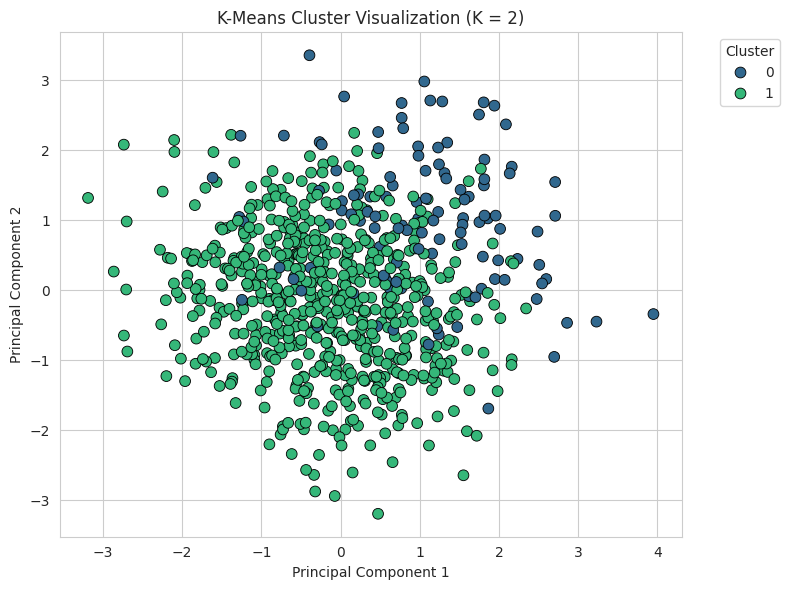

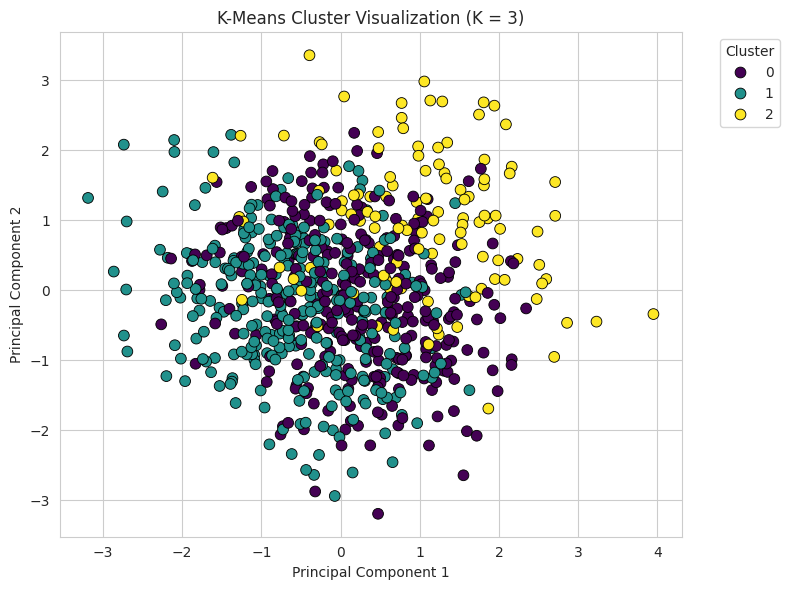

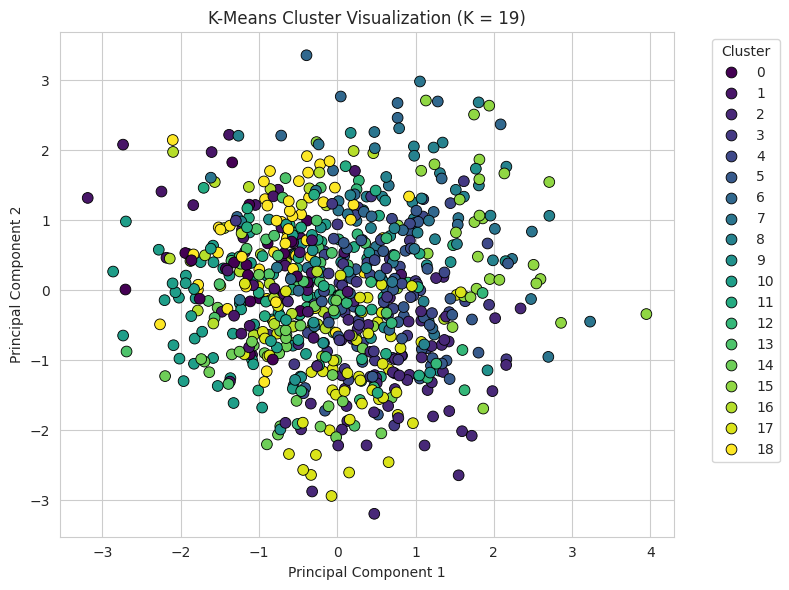

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import pandas as pd

# 1. Apply PCA to reduce the features down to 2 dimensions using your scaled DataFrame
pca = PCA(n_components=2, random_state=42)
principal_components = pca.fit_transform(SG_scaled)

# Create a DataFrame for the PCA results
pca_df = pd.DataFrame(
    data=principal_components,
    columns=['Principal Component 1', 'Principal Component 2']
)

# 2. Loop through each required value of K (2, 3, and 19)
k_values = [2, 3, 19]

for k in k_values:
    # Run k-means clustering with the current K
    kmeans = {2: kmeans_result_2, 3: kmeans_result_3, 19: kmeans_result_19}[k]
    cluster_labels = kmeans.labels_

    # Assign cluster labels to the PCA DataFrame
    pca_df['Cluster'] = cluster_labels

    # 3. Visualize using a scatter plot colored by cluster label
    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        x='Principal Component 1',
        y='Principal Component 2',
        hue='Cluster',
        data=pca_df,
        palette='viridis',
        edgecolor='k',
        s=60,
        legend='full'
    )
    plt.title(f'K-Means Cluster Visualization (K = {k})')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

**Silhouette Plots**

k = 2: average silhouette = 0.145
k = 3: average silhouette = 0.098
k = 19: average silhouette = 0.081


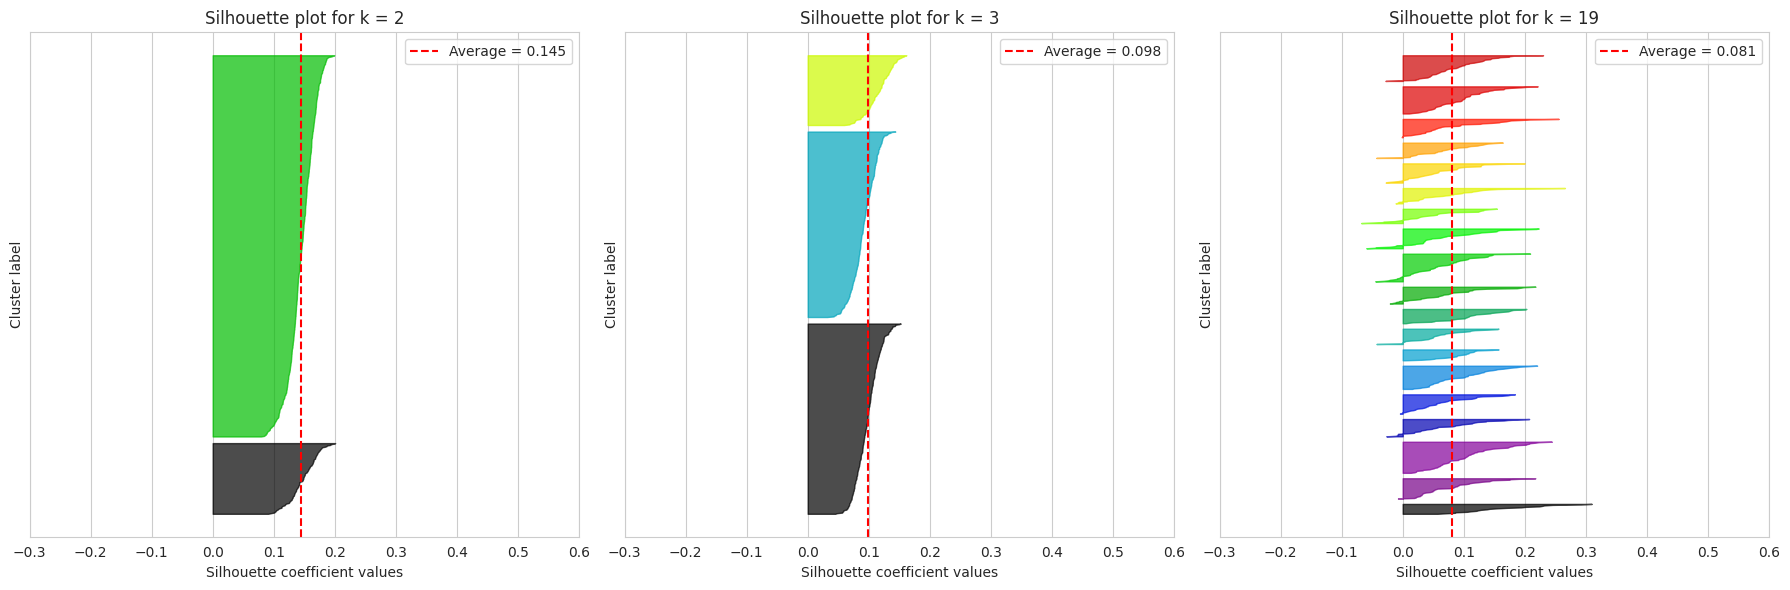

In [44]:
# Silhouette evaluation of the three chosen k values (2, 3, 19)
from sklearn.metrics import silhouette_samples
import matplotlib.cm as cm

models = {2: kmeans_result_2, 3: kmeans_result_3, 19: kmeans_result_19}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (k, model) in zip(axes, models.items()):
    labels = model.labels_
    sample_sil = silhouette_samples(SG_scaled, labels)   # silhouette of every student
    avg_sil = sample_sil.mean()
    print(f"k = {k}: average silhouette = {avg_sil:.3f}")

    y_lower = 10
    for c in range(k):
        c_sil = np.sort(sample_sil[labels == c])
        y_upper = y_lower + len(c_sil)
        color = cm.nipy_spectral(c / k)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, c_sil,facecolor=color, edgecolor=color, alpha=0.7)
        y_lower = y_upper + 10

    ax.axvline(avg_sil, color='red', linestyle='--', label=f'Average = {avg_sil:.3f}')
    ax.set_xlim(-0.3, 0.6)
    ax.set_yticks([])
    ax.set_xlabel('Silhouette coefficient values')
    ax.set_ylabel('Cluster label')
    ax.set_title(f'Silhouette plot for k = {k}')
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


**Conclusion:** The silhouette coefficient measures how compact each cluster is and how well it is separated from the other clusters. Values close to 1 are preferable, and negative values mean that an object is closer to another cluster than to its own.

| k | Average silhouette |
|---|---|
| 2 | 0.145 |
| 3 | 0.098 |
| 19 | 0.081 |

- **k = 2** has the highest average silhouette of the three values (and of all values from 2 to 20).
- **k = 3** is lower, because the extra split divides the students with internet access by extracurricular activities only, so the two new clusters are close to each other.
- **k = 19** has the lowest value, because the 19 small clusters lie close to each other.
- All the values are low (the best is 0.145, far from 1), so the clusters are not strongly separated.

According to the silhouette coefficient, **k = 2 is the best choice** among the three values.


***Compare the results***

---



| k | Chosen by | WSS | Average silhouette | Cluster sizes |
|---|---|---|---|---|
| 2 | Highest silhouette | 8235.4 | **0.145** | 118 / 632 |
| 3 | Elbow method | 7590.5 | 0.098 | 118 / 312 / 320 |
| 19 | Empirical rule | **5424.9** | 0.081 | 21 to 64 |

- **Elbow method:** the WSS decreases as k increases, so k = 19 has the lowest WSS. The turning point of the curve is at k = 3, so k = 3 is the best of the three values.
- **Silhouette coefficient:** k = 2 has the highest average silhouette (0.145), and k = 19 the lowest (0.081), so k = 2 is the best of the three values.

**Agreement between the methods:**

 both methods reject k = 19. For k = 19 the WSS is lowest only because it has the largest number of clusters, and its silhouette is the lowest.
 The methods disagree between k = 2 and k = 3, because the Elbow method measures only compactness (and always rewards a larger k)while the silhouette measures compactness and separation together and penalizes the k = 3 split whose new clusters are close to each other.

**Interpretation:**

for k = 2, the students are split by internet access (118 without and 632 with).
For k = 3, the students with internet access are split further by extracurricular activities.
For k = 19, the clusters are small and show no clear pattern.
 In all cases the clusters are formed by these binary attributes and not by the academic attributes, and the low silhouette values show that the cluster structure is weak.

**Final conclusion:**

k = 19 (empirical rule) is not suitable for this dataset. k = 2 gives the best separation between clusters (highest silhouette), while k = 3 gives the best compactness-to-size balance (elbow).
We consider **k = 2** the best clustering because the silhouette coefficient evaluates both compactness and separation.


# 7. Findings and Discussion

This section discusses what the results of Section 6 mean, which model performs best for each technique, and what information was extracted from the data.

## 7.1 Classification Findings

### 7.1.1 Which model performs best?

Testing accuracy of the decision tree for each attribute selection measure and partition:

| Partition | Gini | Entropy (IG) | Best measure | Entropy advantage |
|---|---|---|---|---|
| 90% / 10% | 17.33% | 25.33% | Entropy | +8.00 points |
| 80% / 20% | 20.00% | 26.67% | Entropy | +6.67 points |
| 70% / 30% | 20.89% | 24.89% | Entropy | +4.00 points |

**Best algorithm for each partition:** entropy (Information Gain) wins in all three partitions, so the ranking of the two measures is consistent.

**Best algorithm overall:** entropy with the **80/20** partition (accuracy 26.67%, weighted F1 = 0.270). This is only about 7 percentage points above the 20% chance level for five balanced classes, while the best Gini model (70/30, 20.89%) is at chance level.

**Overfitting:** all six trees reach 100% training accuracy but only 17% to 27% testing accuracy. Pruning (for example limiting `max_depth` or `min_samples_leaf`) would reduce the overfitting, but it cannot create predictive signal that is not in the attributes.

**Effect of the partition size:** larger training sets did not reliably help. The test sets are small (75, 150 and 225 students), so one extra correct prediction changes the accuracy by 1.33, 0.67 and 0.44 points respectively. Differences between partitions of the same measure (for example 26.67% vs 24.89% for entropy) are therefore within what one random split can produce; the consistent advantage of entropy over Gini is the more reliable result.

### 7.1.2 Interpretation of the confusion matrices

Rows are the actual grades and columns the predicted grades (order A, B, C, D, F). A random classifier would put about 20% of each row on the diagonal.

**Best model (entropy, 80/20):** 40 of 150 students are classified correctly. Grades D (12 of 34, 35.3%) and F (10 of 33, 30.3%) are recognised best, while A (22.2%), B (21.2%) and C (21.7%) are close to chance. The most frequent mistake is F students predicted as A (10 students), so even the extreme grades are confused with each other.

**The strong class changes from model to model:** with entropy 70/30 the best recognised grades are B (38.6%) and C (38.2%); with Gini 70/30 they are A (31.2%) while B drops to 9.1%; with Gini 90/10 grade F is recognised in only 1 of 18 cases (5.6%). A model that finds real structure would favour the same grades in every split.

**Overall pattern:** in every matrix the predictions are spread almost evenly over the five columns and the diagonal is not much stronger than the off-diagonal cells. This confirms that the tree is mostly fitting noise and cannot reliably separate the grades with the available attributes.

### 7.1.3 The decision tree and feature importance

The tree plotted in Section 6.1 (shown to depth 3) starts with a split on `assignment_score` (<= 0.431 after normalisation, about 69 marks on the original scale). The bar chart and table that follow give the importance of all 18 attributes for the best model, i.e. how much each attribute reduced the impurity (entropy) over the whole tree, not only in the first three levels.

Feature importance of the best model (entropy, 80/20):
midterm_score                     0.1679
sleep_hours                       0.1529
assignment_score                  0.1402
attendance_rate                   0.1279
study_hours                       0.1086
stress_level                      0.0717
parent_education_transformed      0.0464
part_time_job_transformed         0.0334
discretized_age_Middle            0.0255
age                               0.0255
extracurricular_transformed       0.0193
internet_access_transformed       0.0169
gender_transformed                0.0166
discretized_age_Young             0.0126
discretized_study_hours_Low       0.0122
discretized_study_hours_Medium    0.0115
discretized_study_hours_High      0.0059
discretized_age_Older             0.0051


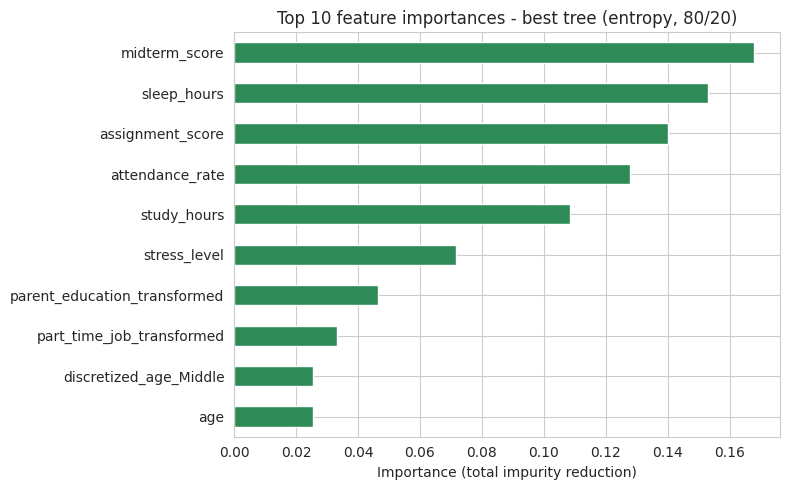


Top 3 attributes: midterm_score (16.8%), sleep_hours (15.3%), assignment_score (14.0%)
Together they account for 46.1% of the total importance.


In [45]:
# Feature importance of the best decision tree (best criterion and partition found in Section 6.1)
importances = pd.Series(best_clf.feature_importances_, index=fn).sort_values(ascending=False)

print(f"Feature importance of the best model ({best_criterion}, {best_partition}):")
print(importances.round(4).to_string())

top10 = importances.head(10)
plt.figure(figsize=(8, 5))
top10[::-1].plot(kind="barh", color="seagreen")
plt.title(f"Top 10 feature importances - best tree ({best_criterion}, {best_partition})")
plt.xlabel("Importance (total impurity reduction)")
plt.tight_layout()
plt.show()

top3 = importances.head(3)
print("\nTop 3 attributes:", ", ".join(f"{name} ({value * 100:.1f}%)" for name, value in top3.items()))
print(f"Together they account for {top3.sum() * 100:.1f}% of the total importance.")

**Interpretation:**

The decision tree uses assignment_score as its root node. However, the feature importance analysis of the complete tree shows that midterm_score has the highest importance (16.79%), followed by sleep_hours (15.29%) and assignment_score (14.02%). Together, these three features account for approximately 46.1% of the total feature importance.

Although these attributes contributed most to the model's decisions, the low testing accuracy (26.67%) and severe overfitting indicate that their importance should be interpreted cautiously. These results do not establish that the attributes have a strong or causal relationship with students' final grades.

### 7.1.4 Extracted information (classification)

 **Solution to the prediction problem:** the best decision tree predicts the final letter grade with 26.67% accuracy, only slightly better than random guessing. With these attributes alone, a student's grade cannot be predicted reliably before the final exam, and the model should not be used to flag individual students.

**Most informative factors:** Based on the complete decision tree's feature importance scores, `midterm_score` (16.79%), `sleep_hours` (15.29%), and `assignment_score` (14.02%) are the three most influential features within the trained model. However, their importance does not necessarily indicate strong predictive relationships because the model performs poorly on unseen data.

 **Weak factors:** lifestyle and background attributes (internet access, part-time job, extracurricular activities, parent education) appear only in lower levels of the tree and their splits barely reduce the entropy, so their effect on the grade is weak in this dataset.

 **Better measure:** Information Gain (entropy) is more suitable than the Gini index for this dataset in all three partitions.

## 7.2 Clustering Findings

### 7.2.1 Choice of K

| K | Chosen by | Average silhouette | Total WSS | Cluster sizes |
|---|---|---|---|---|
| 2 | Highest silhouette | **0.145** | 8235.4 | 118 / 632 |
| 3 | Elbow method | 0.098 | 7590.5 | 118 / 312 / 320 |
| 19 | Empirical rule | 0.081 | **5424.9** | 21 to 64 |

Both methods reject K = 19: its WSS is lowest only because it has the most clusters, and its silhouette is the lowest. The Elbow method favours K = 3 and the silhouette favours K = 2, so there is no literal majority vote selecting one of them. We select **K = 2** because the silhouette coefficient evaluates both compactness and separation, whereas the WSS always rewards a larger K. All silhouette values are low (the best is 0.145), so the cluster structure is weak.

### 7.2.2 Interpretation of the clusters
We compared the final score and grade distribution inside each cluster (for K=2 and K=3 only)


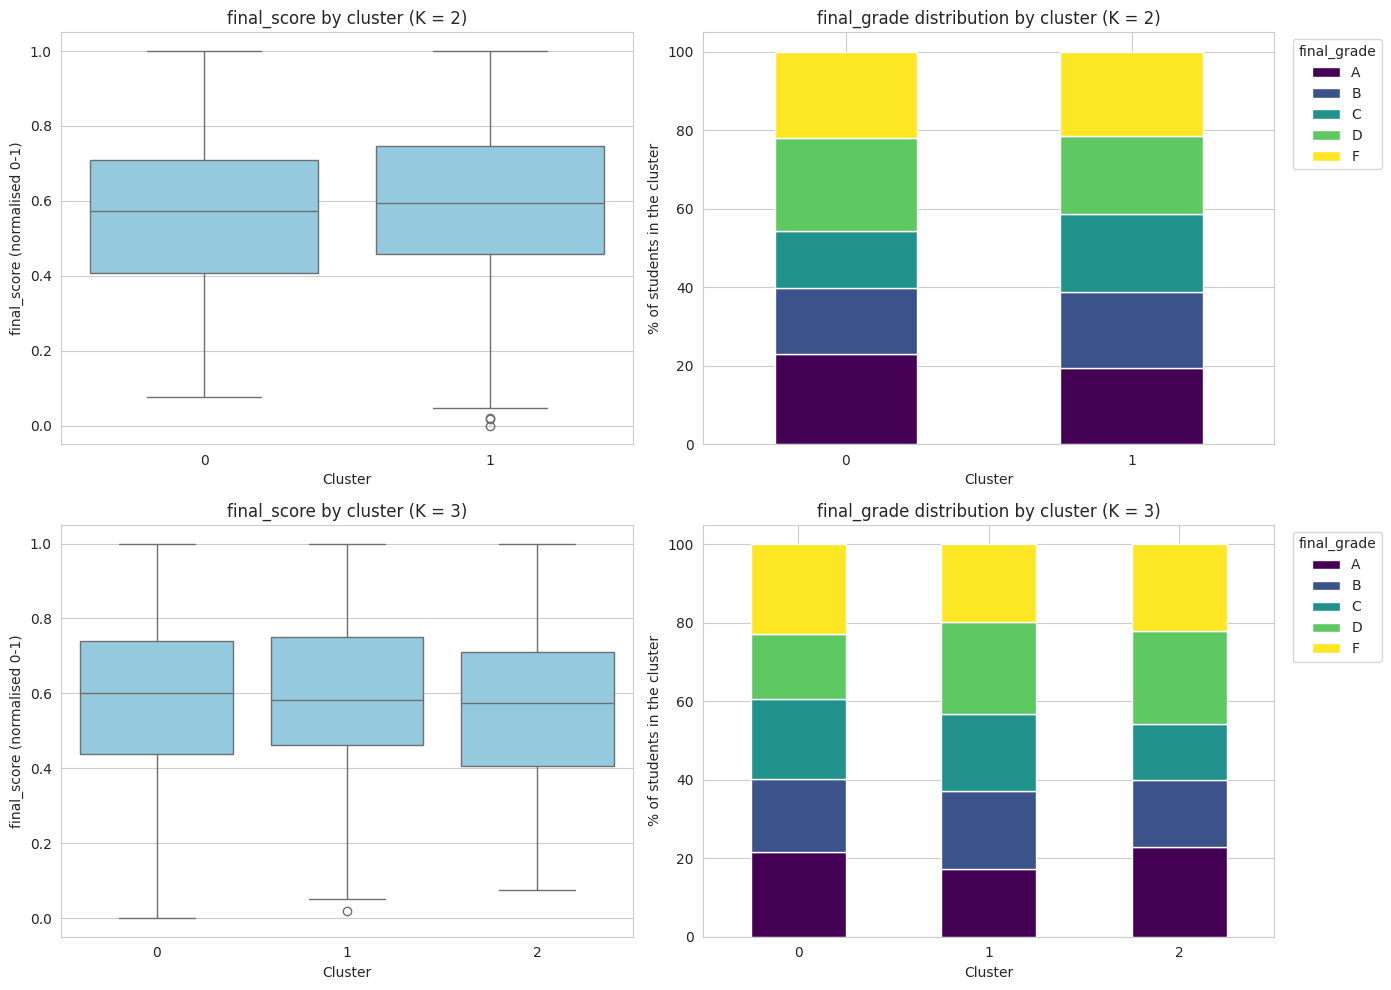

In [46]:
# Compare the clusters with academic performance: final_score and final_grade by cluster
profile_df = pd.read_csv("Dataset/Preprocessed_dataset.csv")
profile_df["cluster_k2"] = kmeans_result_2.labels_
profile_df["cluster_k3"] = kmeans_result_3.labels_
grade_order = ["A", "B", "C", "D", "F"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for row, (k, col) in enumerate([(2, "cluster_k2"), (3, "cluster_k3")]):
    order = sorted(profile_df[col].unique())

    # final_score (normalised 0-1) in each cluster
    sns.boxplot(data=profile_df, x=col, y="final_score", order=order, color="skyblue", ax=axes[row, 0])
    axes[row, 0].set_title(f"final_score by cluster (K = {k})")
    axes[row, 0].set_xlabel("Cluster")
    axes[row, 0].set_ylabel("final_score (normalised 0-1)")

    # share of each final grade in each cluster
    grade_share = (pd.crosstab(profile_df[col], profile_df["final_grade"], normalize="index")
                   .reindex(columns=grade_order) * 100)
    grade_share.plot(kind="bar", stacked=True, colormap="viridis", ax=axes[row, 1])
    axes[row, 1].set_title(f"final_grade distribution by cluster (K = {k})")
    axes[row, 1].set_xlabel("Cluster")
    axes[row, 1].set_ylabel("% of students in the cluster")
    axes[row, 1].tick_params(axis="x", rotation=0)
    axes[row, 1].legend(title="final_grade", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

**Interpretation:**
- **K = 2:** the centroids separate the students almost entirely by internet access: cluster 0 contains the 118 students without internet access (centroid -2.31 on the standardised attribute) and cluster 1 the 632 students with access. The academic attributes (for example the assignment, midterm and final scores) are close to 0 in both centroids.
- **K = 3:** the no-internet group (118 students) stays the same, and the students with internet access are split by extracurricular activities (312 vs 320 students; centroid values of about -1.02 and +0.98). The two new clusters are close to each other, which lowers the silhouette. The academic attributes are again close to 0 in all clusters.
- **Clusters vs performance:** the `final_score` boxplots and the grade distributions of the clusters are compared above. The clusters are formed by the binary attributes, not by academic performance.

### 7.2.3 Extracted information (clustering)

**Natural groups:** the only distinct group in the data is the 118 students (about 16%) without internet access. A second, weaker split divides the remaining students by extracurricular participation.

**Practical use:** the no-internet group is a clear target for support such as campus internet or library access, even though the clustering did not show that this group performs differently on average.

**Best clustering:** K = 2 (silhouette 0.145). All silhouette values are far below 0.5 and the PCA plots show one dense cloud without clear gaps, so students do not form strongly separated natural groups. The clusters are mainly a by-product of the binary attributes, which have large standardised distances between their two values.

## 7.3 Overall Discussion

Both techniques point to the same conclusion: in this dataset the recorded attributes have only a weak relationship with the final grade. The scatter plots in Section 3 already showed grades mixed across all attribute values, the decision tree is only slightly better than chance, and the clusters do not align with academic performance. The dataset looks largely synthetic (for example, students with similar final scores receive very different letter grades), which limits how much real structure any algorithm can discover. The prominence of `assignment_score` in the tree is a model-specific observation, **not evidence of causation**.

- **Best classification model:** Decision Tree with entropy and the 80/20 partition (26.67% accuracy, F1 = 0.270).
- **Best clustering model:** K-Means with K = 2 (silhouette 0.145).
- **Most useful technique for the stated problem:** classification, because it at least ranks the factors that influence the grade and slightly outperforms random guessing. Clustering is more useful for describing the student population (internet access and extracurricular groups) than for explaining performance.

## 7.4 Comparison with the Research Paper

Hasan et al. [2] applied the same two techniques, a decision tree and K-means, to predict student performance in higher education in Bangladesh. Feng et al. [3] similarly used K-means with an optimised choice of k to group students before predicting their performance.

| Aspect | Hasan et al. [2] | Our project |
|---|---|---|
| Decision tree performance | Precision, recall and F1-score of about 0.99 | Accuracy 26.67%, weighted F1 = 0.270 (best model) |
| Clustering result | Three interpretable groups: active learners, passive learners and at-risk students | K = 2 groups defined by internet access (silhouette 0.145); no academic groups |
| Data | Real student records, where grades are strongly linked to engagement and assignment completion | Kaggle student performance dataset; attributes show almost no relationship with the grade |
| Validation | 10-fold cross-validation and a tuned tree | Single hold-out splits (70/30, 80/20, 90/10) and unpruned trees |
| Clustering features | Chosen around learning behaviour | Dominated by binary attributes (internet access, extracurricular) |

Our results are much lower for three main reasons: (1) their data comes from real records with strong links between engagement and grades, while ours shows almost no such link; (2) they used cross-validation and a tuned tree, whereas we used single hold-out splits with unpruned trees; and (3) their clustering features were chosen around learning behaviour, while ours are dominated by binary attributes. Like the papers, our tree identifies assignment performance as a key factor, and our choice of k using both the Elbow and the silhouette methods follows the same validation practice.

## 7.5 Limitations and Future Work

-Prune the decision tree (`max_depth`, `min_samples_leaf`) and use k-fold cross-validation for more stable accuracy estimates.

-Try other classifiers (Random Forest, Naive Bayes) and compare them with the decision tree.

-Use an institutional dataset with stronger links between behaviour and grades.

-Cluster on numeric academic and behavioural attributes only to avoid binary attributes dominating the distance.

# 8. References

[1] krisnadwikialdi, “Student Performance Dataset,” Kaggle. [Online]. Available: https://www.kaggle.com/datasets/krisnadwikialdi/student-performance-dataset

[2] M. M. Hasan *et al*., “Predicting student performance and identifying learning behaviors using decision trees and K-means clustering,” *International Journal of Evaluation and Research in Education*, vol. 14, no. 5, 2025, doi: 10.11591/ijere.v14i5.33815.

[3] G. Feng, M. Fan, and Y. Chen, “Analysis and prediction of students’ academic performance based on educational data mining,” *IEEE Access*, vol. 10, 2022, doi: 10.1109/ACCESS.2022.3151652.

[4] J. Han, M. Kamber, and J. Pei, *Data Mining: Concepts and Techniques*, 3rd ed. Morgan Kaufmann, 2012.

[5] F. Pedregosa *et al*., “Scikit-learn: Machine learning in Python,” *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.
